# 04 · Modelado de la solución

**Qué hace este notebook:** entrena y valida el modelo que predice la **demanda de cada estación de Ecobici, hora por hora, para el día siguiente**, y lo guarda para usarlo sin reentrenar. Con las predicciones arma las dos salidas que motivan el proyecto: qué estaciones van a quedar **vacías o llenas** (para planificar el rebalanceo) y cuáles conviene **ampliar**.

**Entrada:** `data/processed/dataset_estacion_hora.parquet` (tercer notebook): una fila por estación activa y hora, del 01/01/2024 al 31/08/2026, con la partición `train` / `test` ya hecha.

**Salidas** (en `models/`): los modelos entrenados (`.joblib`), los grupos de estaciones y un `metadata.json` con las variables, los hiperparámetros, las métricas y la consulta que arma las variables.

**Targets.** `retiros` (el target principal) y `arribos`. La diferencia `arribos − retiros` es el **flujo neto** de la estación: si es negativo la estación se vacía, si es positivo se llena.

**Tiempo de ejecución:** unos 20 minutos en una Mac con 16 GB de RAM; la mayor parte se va en la búsqueda de hiperparámetros y la validación cruzada (secciones 7 y 8).

## 0. Configuración

- **Corte de test:** desde el 01/06/2026, el mismo del tercer notebook. El test **no se usa** hasta la sección 9: toda decisión (variables, hiperparámetros, censura) se toma con el train.
- **Validación:** dentro del train, una ventana para la búsqueda de hiperparámetros (junio a agosto de 2025) y, después, tres pliegues temporales de tres meses para comparar modelos (sección 4).
- **Modelos:** se usa sólo `scikit-learn`, que ya es dependencia del proyecto. El modelo principal es `HistGradientBoostingRegressor`, la implementación de *gradient boosting* por histogramas de scikit-learn, inspirada en LightGBM (ver sección 1).

In [1]:
from pathlib import Path
import json
import time
import warnings

import duckdb
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from scipy.stats import loguniform, spearmanr
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import PoissonRegressor
from sklearn.metrics import (mean_absolute_error, mean_poisson_deviance, r2_score,
                             root_mean_squared_error, silhouette_score)
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

REPO_DIR = Path("..").resolve()
PROCESSED_DIR = REPO_DIR / "data" / "processed"
DATASET = PROCESSED_DIR / "dataset_estacion_hora.parquet"
MODELS_DIR = REPO_DIR / "models"
MODELS_DIR.mkdir(exist_ok=True)

TEST_DESDE = pd.Timestamp("2026-06-01")
PLIEGUES = [  # (inicio, fin) de cada ventana de validación dentro del train
    (pd.Timestamp("2025-09-01"), pd.Timestamp("2025-12-01")),
    (pd.Timestamp("2025-12-01"), pd.Timestamp("2026-03-01")),
    (pd.Timestamp("2026-03-01"), pd.Timestamp("2026-06-01")),
]
BUSQUEDA = (pd.Timestamp("2025-06-01"), pd.Timestamp("2025-09-01"))  # ventana de validación de la búsqueda
SEMILLA = 42
MUESTRA_GLM = 1_000_000  # filas para el modelo lineal (ver sección 6)

BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#8c8c86"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold"})

warnings.filterwarnings("ignore", message=".*'generic' unit for NumPy timedelta.*")  # aviso interno de pandas con numpy 2

assert DATASET.exists(), f"No se encontró {DATASET}. Correr antes el notebook 03."
print("scikit-learn", sklearn.__version__)
print("Entrada:", DATASET)
print("Salidas:", MODELS_DIR)

scikit-learn 1.9.1
Entrada: /Users/harry/Facultad/CDA/EcobiciScraping/ecobici-demand-predictor/data/processed/dataset_estacion_hora.parquet
Salidas: /Users/harry/Facultad/CDA/EcobiciScraping/ecobici-demand-predictor/models


## 1. Enfoque adoptado y justificación

**Tipo de problema.** Aprendizaje **supervisado de regresión**: se conocen las variables $X$ (calendario, clima, demanda pasada, estado de la estación) y se quiere estimar un número, la cantidad de retiros (o arribos) de una estación en una hora.

**Qué se predice y cuándo.** El uso es operativo: el equipo de logística planifica el rebalanceo del día con anticipación. Por eso el modelo predice **las 24 horas del día siguiente** con lo que se sabe **al cierre del día anterior**. Esto define qué variables se pueden usar:

| Se puede usar | No se puede usar |
|---|---|
| Calendario del día a predecir (hora, día, feriado) | Retiros o arribos de las 24 h previas a la hora a predecir |
| Clima de la hora (en producción, el pronóstico) | Estado de la estación en la **misma** hora (es en parte consecuencia del target, como advirtió el tercer notebook) |
| Demanda y estado de la estación con **24 h o más** de rezago | |

**Por qué estas técnicas** (de las vistas en la clase de regresión):

| Técnica | Rol | Motivo |
|---|---|---|
| Promedios históricos y "semana anterior" | **Baselines** | Un modelo sólo vale si le gana a la regla que usaría un operador sin modelo |
| Regresión de **Poisson** (modelo lineal generalizado) | Modelo lineal de referencia | El target es un **conteo** con exceso de ceros: la regresión lineal por mínimos cuadrados supone errores normales con varianza constante, y acá la varianza crece con la media (heterocedasticidad). Poisson modela el logaritmo de la media y nunca predice valores negativos. Además es interpretable |
| **Gradient boosting** con pérdida de Poisson (`HistGradientBoostingRegressor`) | **Modelo principal** | Es el algoritmo de LightGBM/XGBoost (árboles secuenciales que corrigen el residuo del anterior, crecimiento por hojas, histogramas): capta no linealidades e interacciones (hora × tipo de día × estación), **acepta faltantes** (las variables de las fotos faltan en el 24 % de las filas) y entrena 8 M de filas en alrededor de un minuto. Se usa la implementación de scikit-learn porque LightGBM y XGBoost necesitan instalar OpenMP aparte en macOS, y así el proyecto sigue reproducible con las mismas dependencias |
| *K-means* sobre perfiles horarios (no supervisado) | Análisis complementario | Agrupa estaciones por **cuándo** se vacían o se llenan; sirve para leer los errores y para el rebalanceo |

**Técnicas descartadas:**

- **SVR y redes MLP:** el SVR es muy costoso con datasets grandes (la clase lo marca como su principal desventaja; con 8 M de filas no es viable), y el MLP necesita imputar los faltantes y no suele superar al boosting en datos tabulares.
- **ARIMA / Prophet:** modelan **una** serie por vez; harían falta ~400 modelos y no incorporan fácilmente clima, feriados ni el estado de las estaciones. Las variables con rezago le dan al boosting la misma información autorregresiva.

**Cómo se valida:** con particiones **temporales** (nunca al azar) y métricas para conteos (sección 3). El test (junio a agosto de 2026) se usa una sola vez, al final.

## 2. Variables con rezago

Se calculan con funciones de ventana de DuckDB sobre la grilla completa. La ventana se define por **tiempo** (`RANGE ... INTERVAL`) y no por filas: en la grilla faltan las horas en que se cortó toda la red, así que "la fila anterior" no siempre es "la hora anterior". Todas las ventanas terminan **24 h o más antes** de la hora a predecir.

| Variable | Definición |
|---|---|
| `ret_lag24`, `arr_lag24` | Retiros / arribos de la misma estación a la misma hora del día anterior |
| `ret_lag168`, `arr_lag168` | Ídem, una semana antes |
| `ret_misma_hora_7d`, `arr_misma_hora_7d` | Promedio de la misma hora en los 7 días anteriores |
| `ret_dia_anterior`, `arr_dia_anterior` | Total de las 24 h que terminan 24 h antes |
| `ret_media_28d`, `arr_media_28d` | Promedio horario de los últimos 28 días: el **nivel** de la estación |
| `capacidad_util_dia_ant`, `bicis_rotas_dia_ant`, `pct_capacidad_rota_dia_ant` | Estado de la estación (fotos) promediado en las 24 h que terminan 24 h antes |
| `prop_vacia_dia_ant`, `prop_llena_dia_ant` | Fracción de fotos en que estuvo vacía / llena en ese mismo período |

Las medias de 28 días reemplazan al `station_id` como variable: le dicen al modelo cuánto se usa cada estación sin agregar 400 columnas, y se actualizan solas si una estación cambia de nivel.

La consulta se guarda como texto porque es parte del modelo: en producción hay que construir las variables exactamente igual (se persiste en la sección 12).

In [2]:
CONSULTA_VARIABLES = '''
WITH base AS (
    SELECT *, CAST(timezone('America/Argentina/Buenos_Aires', hora_local) AS TIMESTAMP) AS ts
    FROM read_parquet('{fuente}')
    WHERE hora_local >= TIMESTAMPTZ '{desde}'  -- para predecir un día alcanza con los 29 días previos
)
SELECT
    station_id, ts, split, retiros, arribos,
    hora, dia_semana, mes, es_fin_de_semana, es_feriado, dia_habil,
    temperatura_c, precipitacion_mm, viento_kmh, llueve, lat, lon,
    -- Misma hora que el target: no son variables del modelo, sólo para censura y análisis
    sin_fotos, capacidad_publicada, prop_vacia, prop_llena,
    CAST(flag_vacia AS FLOAT) AS flag_vacia,
    CAST(flag_llena_por_rotas AS FLOAT) AS flag_llena_por_rotas,
    CAST(sin_alquiler AS FLOAT) AS sin_alquiler,
    -- Demanda pasada (24 h o más antes)
    CAST(max(retiros) OVER lag24 AS FLOAT)            AS ret_lag24,
    CAST(max(retiros) OVER lag168 AS FLOAT)           AS ret_lag168,
    CAST(avg(retiros) OVER misma_hora_7d AS FLOAT)    AS ret_misma_hora_7d,
    CAST(sum(retiros) OVER dia_anterior AS FLOAT)     AS ret_dia_anterior,
    CAST(avg(retiros) OVER ultimos_28d AS FLOAT)      AS ret_media_28d,
    CAST(max(arribos) OVER lag24 AS FLOAT)            AS arr_lag24,
    CAST(max(arribos) OVER lag168 AS FLOAT)           AS arr_lag168,
    CAST(avg(arribos) OVER misma_hora_7d AS FLOAT)    AS arr_misma_hora_7d,
    CAST(sum(arribos) OVER dia_anterior AS FLOAT)     AS arr_dia_anterior,
    CAST(avg(arribos) OVER ultimos_28d AS FLOAT)      AS arr_media_28d,
    -- Estado de la estación el día anterior (fotos)
    CAST(avg(capacidad_util) OVER dia_anterior AS FLOAT)     AS capacidad_util_dia_ant,
    CAST(avg(bicis_rotas) OVER dia_anterior AS FLOAT)        AS bicis_rotas_dia_ant,
    CAST(avg(pct_capacidad_rota) OVER dia_anterior AS FLOAT) AS pct_capacidad_rota_dia_ant,
    CAST(avg(prop_vacia) OVER dia_anterior AS FLOAT)         AS prop_vacia_dia_ant,
    CAST(avg(prop_llena) OVER dia_anterior AS FLOAT)         AS prop_llena_dia_ant
FROM base
WINDOW
    lag24 AS (PARTITION BY station_id ORDER BY ts
              RANGE BETWEEN INTERVAL 24 HOURS PRECEDING AND INTERVAL 24 HOURS PRECEDING),
    lag168 AS (PARTITION BY station_id ORDER BY ts
               RANGE BETWEEN INTERVAL 168 HOURS PRECEDING AND INTERVAL 168 HOURS PRECEDING),
    misma_hora_7d AS (PARTITION BY station_id, hora ORDER BY ts
                      RANGE BETWEEN INTERVAL 7 DAYS PRECEDING AND INTERVAL 1 DAYS PRECEDING),
    dia_anterior AS (PARTITION BY station_id ORDER BY ts
                     RANGE BETWEEN INTERVAL 47 HOURS PRECEDING AND INTERVAL 24 HOURS PRECEDING),
    ultimos_28d AS (PARTITION BY station_id ORDER BY ts
                    RANGE BETWEEN INTERVAL 28 DAYS PRECEDING AND INTERVAL 24 HOURS PRECEDING)
ORDER BY station_id, ts
'''

inicio = time.perf_counter()
con = duckdb.connect()
con.execute("SET enable_progress_bar = false")
df = con.execute(CONSULTA_VARIABLES.format(fuente=DATASET.as_posix(), desde="2000-01-01")).df()
df["hora_dia_habil"] = (df.hora + 24 * df.dia_habil).astype("int8")  # interacción para el modelo lineal
print(f"{len(df):,} filas × {df.shape[1]} columnas en {time.perf_counter() - inicio:.0f} s "
      f"({df.memory_usage(deep=True).sum() / 1e9:.1f} GB)")

8,992,349 filas × 40 columnas en 24 s (1.9 GB)


**Control de fuga de información.** Se recalculan dos de las variables con `pandas` en tres estaciones al azar, desplazando la serie en el tiempo, y se comparan con las de DuckDB. Si alguna ventana incluyera la hora a predecir, no coincidirían.

In [3]:
for estacion in df.station_id.drop_duplicates().sample(3, random_state=SEMILLA):
    serie = df.loc[df.station_id == estacion].set_index("ts")
    esperado = serie.retiros.shift(freq="24h").reindex(serie.index)
    assert np.allclose(esperado.fillna(-1), serie.ret_lag24.fillna(-1)), estacion
    # total de las 24 h (t-47 h ... t-24 h); se compara donde la hora t-24 existe en la grilla
    esperado = serie.retiros.rolling("24h").sum().shift(freq="24h").reindex(serie.index)
    hay = esperado.notna()
    assert np.allclose(esperado[hay], serie.ret_dia_anterior[hay]), estacion
print("Rezagos verificados: ninguna ventana incluye la hora a predecir.")

CALENDARIO = ["hora", "dia_semana", "mes", "es_fin_de_semana", "es_feriado", "dia_habil"]
CLIMA = ["temperatura_c", "precipitacion_mm", "viento_kmh", "llueve"]
UBICACION = ["lat", "lon"]
REZAGOS = ["ret_lag24", "ret_lag168", "ret_misma_hora_7d", "ret_dia_anterior", "ret_media_28d",
           "arr_lag24", "arr_lag168", "arr_misma_hora_7d", "arr_dia_anterior", "arr_media_28d"]
ESTADO = ["capacidad_util_dia_ant", "bicis_rotas_dia_ant", "pct_capacidad_rota_dia_ant",
          "prop_vacia_dia_ant", "prop_llena_dia_ant"]
VARIABLES = CALENDARIO + CLIMA + UBICACION + REZAGOS + ESTADO

X = df[VARIABLES]
es_train = df.split.eq("train").to_numpy()
es_test = ~es_train
print(f"{len(VARIABLES)} variables")
(X.isna().mean().mul(100).round(1).rename("% faltantes")
  .to_frame().query("`% faltantes` > 0").sort_values("% faltantes", ascending=False))

Rezagos verificados: ninguna ventana incluye la hora a predecir.


27 variables


,% faltantes
capacidad_util_dia_ant,23.8
bicis_rotas_dia_ant,23.8
pct_capacidad_rota_dia_ant,23.8
prop_vacia_dia_ant,23.8
prop_llena_dia_ant,23.8
ret_lag168,0.8
arr_lag168,0.8
ret_lag24,0.2
arr_lag24,0.2
ret_misma_hora_7d,0.1


**Lectura.** - Las variables de **estado de la estación** faltan en el 23,8 % de las filas: las horas cuyo día anterior no tiene fotos (enero a julio de 2024, el hueco de julio de 2025 y parte del test). El boosting las acepta como faltantes; la regresión de Poisson necesita imputarlas (sección 6).
- Los **rezagos de demanda** casi no faltan (< 1 %): sólo en la primera semana de cada estación y alrededor de las horas en que se cortó la red.

## 3. Métricas

| Métrica | Qué mide | Por qué se usa (o no) |
|---|---|---|
| **Devianza de Poisson** | Qué tan probable es lo observado si la demanda sigue una Poisson con la media predicha | **Métrica principal.** Es la que corresponde a un conteo: penaliza fuerte predecir ~0 donde hubo viajes. Es la que se minimiza al entrenar |
| **RMSE** | Error cuadrático, en viajes | Castiga los errores grandes (las horas pico, que son las que importan para el rebalanceo) |
| **MAE** | Error absoluto, en viajes | Se informa, pero **engaña con este target**: con 60 % de ceros, predecir siempre 0 tiene un MAE bajo. Se ve en la sección 5 |
| **R²** y **RAE** | Error relativo a predecir la media | Sin unidades; el RAE no tiene problema con los ceros |
| **Sesgo %** | Total predicho vs. total observado | Un modelo que subestima de forma sistemática deja estaciones vacías |
| **MAE y WAPE diarios** | Error en el **total del día** de cada estación | Es la escala de decisión del rebalanceo. WAPE = Σ\|error\| / Σ real |

El **MAPE** no se usa: divide por el valor real, que es 0 en la mayoría de las filas.

Para la devianza, las predicciones se recortan a un mínimo de 10⁻⁶ (con una predicción de 0 donde hubo viajes es infinita). Sólo afecta al baseline "Cero", cuya devianza depende de ese mínimo y no hay que leerla como un número exacto.

In [4]:
def metricas(y, pred):
    y = np.asarray(y, dtype=float)
    pred = np.asarray(pred, dtype=float)
    return {
        # la devianza exige predicciones > 0: se recorta sólo acá, el resto de las métricas usa la predicción tal cual
        "Devianza Poisson": mean_poisson_deviance(y, np.clip(pred, 1e-6, None)),
        "RMSE": root_mean_squared_error(y, pred),
        "MAE": mean_absolute_error(y, pred),
        "R²": r2_score(y, pred),
        "RAE": np.abs(pred - y).sum() / np.abs(y - y.mean()).sum(),
        "Sesgo %": 100 * (pred.sum() / y.sum() - 1),
    }


def metricas_diarias(datos, y, pred):
    diario = (pd.DataFrame({"station_id": datos.station_id.to_numpy(), "fecha": datos.ts.dt.floor("D").to_numpy(),
                            "real": np.asarray(y), "pred": np.asarray(pred)})
                .groupby(["station_id", "fecha"])[["real", "pred"]].sum())
    error = (diario.pred - diario.real).abs()
    return {"MAE diario": error.mean(), "WAPE diario %": 100 * error.sum() / diario.real.sum()}


def evaluar(datos, y, predicciones):
    filas = {nombre: {**metricas(y, pred), **metricas_diarias(datos, y, pred)}
             for nombre, pred in predicciones.items()}
    return pd.DataFrame(filas).T

## 4. Esquema de validación

La partición del tercer notebook deja el **test** (junio a agosto de 2026) aparte. Dentro del train se usa **validación cruzada temporal con origen móvil**: en cada pliegue se entrena con todo lo anterior a una fecha y se valida con los tres meses siguientes. Es la versión temporal de la validación cruzada (como `TimeSeriesSplit`, pero con cortes por fecha): nunca se entrena con datos posteriores a los que se validan.

- La **búsqueda de hiperparámetros** (sección 7) usa una ventana **aparte y anterior** a los pliegues: junio a agosto de 2025, que además es invierno, como el test. Si se eligieran los hiperparámetros con uno de los pliegues, el resultado de ese pliegue en la validación cruzada quedaría optimista (se habría elegido justamente lo que mejor le va).
- La **comparación de modelos** (sección 8) usa los tres pliegues, y así se ve si el resultado es estable en distintas épocas del año.

In [5]:
def particion(inicio, fin):
    entrenamiento = es_train & (df.ts < inicio).to_numpy()
    validacion = es_train & (df.ts >= inicio).to_numpy() & (df.ts < fin).to_numpy()
    return entrenamiento, validacion


def describir(nombre, inicio, fin):
    entrenamiento, validacion = particion(inicio, fin)
    return {"pliegue": nombre, "entrena hasta": inicio - pd.Timedelta(hours=1),
            "valida": f"{inicio:%d/%m/%Y} → {fin - pd.Timedelta(days=1):%d/%m/%Y}",
            "filas train": entrenamiento.sum(), "filas validación": validacion.sum()}


pd.DataFrame([describir("búsqueda", *BUSQUEDA)]
             + [describir(i, inicio, fin) for i, (inicio, fin) in enumerate(PLIEGUES, start=1)]
             + [{"pliegue": "test", "entrena hasta": TEST_DESDE - pd.Timedelta(hours=1), "valida": "01/06/2026 → 31/08/2026",
      "filas train": es_train.sum(), "filas validación": es_test.sum()}]).set_index("pliegue")

,entrena hasta,valida,filas train,filas validación
pliegue,,,,
búsqueda,2025-05-31 23:00:00,01/06/2025 → 31/08/2025,4626681,883200
1,2025-08-31 23:00:00,01/09/2025 → 30/11/2025,5509881,871532
2,2025-11-30 23:00:00,01/12/2025 → 28/02/2026,6381413,862734
3,2026-02-28 23:00:00,01/03/2026 → 31/05/2026,7244147,877449
test,2026-05-31 23:00:00,01/06/2026 → 31/08/2026,8121596,870753


## 5. Baselines

Reglas que usaría un operador sin modelo. Todas usan sólo información del pasado:

- **Cero:** predecir que no habrá viajes. Sirve para calibrar las métricas.
- **Semana anterior:** lo que pasó a la misma hora siete días antes.
- **Promedio 7 días, misma hora:** el promedio de esa hora en la última semana.
- **Media histórica estación × hora × tipo de día:** el promedio de esa estación a esa hora, en días hábiles o no hábiles, calculado con todo el train disponible. Es el baseline recomendado al final del tercer notebook.

In [6]:
def predecir_baselines(entrenamiento, validacion, target):
    prefijo = target[:3]
    datos = df.loc[validacion]
    claves = ["station_id", "hora", "dia_habil"]
    media = df.loc[entrenamiento].groupby(claves)[target].mean().rename("media")
    historica = datos[claves].join(media, on=claves)["media"].fillna(df.loc[entrenamiento, target].mean())
    return {
        "Cero": np.zeros(len(datos)),
        "Semana anterior": datos[f"{prefijo}_lag168"].fillna(datos[f"{prefijo}_misma_hora_7d"]).fillna(0).to_numpy(),
        "Promedio 7 días, misma hora": datos[f"{prefijo}_misma_hora_7d"].fillna(0).to_numpy(),
        "Media histórica estación × hora × tipo de día": historica.to_numpy(),
    }


entr_val, val = particion(*PLIEGUES[-1])
bases_val = predecir_baselines(entr_val, val, "retiros")
evaluar(df.loc[val], df.loc[val, "retiros"], bases_val).round(3)

,Devianza Poisson,RMSE,MAE,R²,RAE,Sesgo %,MAE diario,WAPE diario %
Cero,25.447,1.827,0.919,-0.338,0.855,-100.000,22.046,100.000
Semana anterior,8.188,1.651,0.931,-0.093,0.867,2.795,8.601,39.016
"Promedio 7 días, misma hora",1.855,1.340,0.852,0.280,0.793,1.790,9.635,43.706
Media histórica estación × hora × tipo de día,1.192,1.224,0.772,0.399,0.718,-0.039,6.954,31.544


**Lectura.** - **El MAE engaña:** predecir siempre 0 (MAE 0,919) tiene mejor MAE que copiar la semana anterior (0,931), aunque no sirve para nada: su WAPE diario es 100 %. Por eso la métrica principal es la **devianza de Poisson**, y para la decisión se mira el **WAPE diario**.
- **Semana anterior** usa una sola observación, que es muy ruidosa: R² negativo. Promediar los 7 días ya reduce mucho la devianza (de 8,2 a 1,9).
- **La media histórica** por estación, hora y tipo de día es el mejor baseline: devianza 1,19, R² 0,40, WAPE diario 31,5 % y sin sesgo. **Es la referencia que el modelo tiene que superar.**

## 6. Modelo lineal: regresión de Poisson

$$\log \mathbb{E}[\text{retiros}] = \beta_0 + \beta_1 x_1 + \dots + \beta_n x_n$$

Es un modelo lineal en el **logaritmo** de la demanda: cada coeficiente es un efecto **multiplicativo** ($e^{\beta}$ es cuánto se multiplica la demanda esperada). Preprocesamiento, dentro de un `Pipeline` para que se ajuste sólo con el train de cada pliegue:

- **One-hot** de `hora × día hábil` (48 categorías: el pico de las 8 h sólo existe en días hábiles, y un modelo lineal no lo descubre solo), `dia_semana` y `mes`.
- **Rezagos:** `log1p` (son conteos muy asimétricos y el modelo trabaja en escala logarítmica) y estandarización.
- **Faltantes:** el modelo lineal no los acepta. Se imputan con la mediana del train **y se agrega un indicador** de faltante, para que el modelo sepa que el valor no es real (el tercer notebook evitó imputar el dataset; acá la imputación queda dentro del modelo y es explícita).
- **Regularización L2** suave (`alpha`), porque las categorías one-hot son colineales.

Se entrena con una muestra de 1 M de filas: el ajuste por `lbfgs` con ~100 columnas densas es lento con 8 M, y con 1 M los coeficientes ya son estables.

In [7]:
def nuevo_glm():
    preprocesamiento = ColumnTransformer([
        ("categoricas", OneHotEncoder(handle_unknown="ignore"), ["hora_dia_habil", "dia_semana", "mes"]),
        ("numericas", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()),
         CLIMA + UBICACION + ["es_feriado"] + ESTADO),
        ("rezagos", make_pipeline(FunctionTransformer(np.log1p, feature_names_out="one-to-one"),
                                  SimpleImputer(strategy="median", add_indicator=True), StandardScaler()),
         REZAGOS),
    ], sparse_threshold=0)
    return make_pipeline(preprocesamiento, PoissonRegressor(alpha=1e-4, max_iter=1000))


COLUMNAS_GLM = VARIABLES + ["hora_dia_habil"]


def entrenar_glm(mascara, target):
    rng = np.random.default_rng(SEMILLA)  # generador propio: la muestra no depende de qué celdas corrieron antes
    filas = np.sort(rng.choice(np.flatnonzero(mascara), size=min(MUESTRA_GLM, mascara.sum()), replace=False))
    modelo = nuevo_glm()
    modelo.fit(df.iloc[filas][COLUMNAS_GLM], df.iloc[filas][target])
    return modelo


inicio = time.perf_counter()
glm_val = entrenar_glm(entr_val, "retiros")
print(f"Entrenado en {time.perf_counter() - inicio:.0f} s · iteraciones: {glm_val[-1].n_iter_}")
pred_glm_val = glm_val.predict(df.loc[val, COLUMNAS_GLM])
evaluar(df.loc[val], df.loc[val, "retiros"],
        {"Media histórica estación × hora × tipo de día": bases_val["Media histórica estación × hora × tipo de día"],
         "Regresión de Poisson": pred_glm_val}).round(3)

Entrenado en 9 s · iteraciones: 255


,Devianza Poisson,RMSE,MAE,R²,RAE,Sesgo %,MAE diario,WAPE diario %
Media histórica estación × hora × tipo de día,1.192,1.224,0.772,0.399,0.718,-0.039,6.954,31.544
Regresión de Poisson,1.183,1.230,0.777,0.394,0.723,1.016,6.204,28.141


**Interpretación de coeficientes.** Las variables entran estandarizadas, así que $e^{\beta}$ es el factor por el que se multiplica la demanda esperada cuando la variable sube **un desvío estándar**, con todo lo demás fijo. Para leer el efecto en las unidades originales (un 0/1 que pasa de 0 a 1, un milímetro de lluvia, un grado) se divide el coeficiente por el desvío del escalador: es la última columna. Para los rezagos, que entran como $\log(1+x)$, no tiene una lectura directa y se deja vacía.

In [8]:
nombres = glm_val[0].get_feature_names_out()
coeficientes = pd.Series(glm_val[-1].coef_, index=nombres)
numericos = coeficientes[~coeficientes.index.str.startswith("categoricas")]
numericos.index = numericos.index.str.split("__", n=1).str[1]
paso_numericas = glm_val[0].named_transformers_["numericas"]
desvios = pd.Series(paso_numericas[-1].scale_, index=paso_numericas[:-1].get_feature_names_out())
(pd.DataFrame({"coeficiente": numericos,
               "factor por desvío (e^β)": np.exp(numericos),
               "factor por unidad": np.exp(numericos / desvios.reindex(numericos.index))})
   .loc[numericos.abs().sort_values(ascending=False).index]
   .head(12).round(3))

,coeficiente,factor por desvío (e^β),factor por unidad
ret_media_28d,0.360,1.434,NaN
ret_misma_hora_7d,0.313,1.368,NaN
arr_media_28d,-0.137,0.872,NaN
precipitacion_mm,-0.108,0.897,0.871
llueve,-0.086,0.917,0.750
arr_dia_anterior,0.057,1.058,NaN
es_feriado,-0.054,0.947,0.789
ret_lag168,0.045,1.046,NaN
lon,0.040,1.041,2.533
viento_kmh,-0.032,0.969,0.995


**Lectura.** - **Rendimiento:** la regresión de Poisson apenas mejora a la media histórica hora por hora (devianza 1,183 contra 1,192), pero mejora más en el total diario (WAPE 28,1 % contra 31,5 %): los rezagos le permiten seguir el nivel reciente de cada estación.
- **Coeficientes:** dominan el **nivel de la estación** (`ret_media_28d`: un desvío más multiplica la demanda por 1,43) y la **misma hora de la última semana** (×1,37).
- **Lluvia y feriados, en unidades originales** (última columna):
  - Una hora **con lluvia** tiene un 25 % menos de retiros por el solo hecho de llover (`llueve`, ×0,75).
  - **Cada milímetro** adicional resta otro 13 % (×0,87).
  - Un **feriado** tiene un 21 % menos de retiros que un día no hábil común a la misma hora (×0,79), además del efecto del tipo de día.
- **Cuidado con `arr_media_28d` negativo:** está casi perfectamente correlacionada con `ret_media_28d` (lo que sale de una estación vuelve a entrar). Con variables colineales el signo de cada coeficiente por separado no se puede interpretar; lo que importa es el efecto conjunto. Por lo mismo, el factor de `lon` por grado (×2,5) no tiene lectura útil: un grado de longitud es más ancho que toda la ciudad.
- **Límite del modelo lineal:** sólo capta las interacciones que se le dan explícitamente (hora × día hábil). Cómo cambia el efecto de la lluvia según la hora o la estación tiene que venir de un modelo no lineal.

## 7. Gradient boosting con pérdida de Poisson

### 7.1 Búsqueda de hiperparámetros

Se usa **búsqueda aleatoria** (`RandomizedSearchCV`), que según la clase encuentra buenos valores de los hiperparámetros importantes con muchas menos corridas que una grilla. Diez combinaciones, validadas con la ventana de búsqueda (junio a agosto de 2025, sección 4) y elegidas por devianza de Poisson. Para que la búsqueda entre en tiempo se entrena con una muestra al azar del 40 % de las filas anteriores a esa ventana; la validación se hace con la ventana completa.

| Hiperparámetro | Rango | Qué controla |
|---|---|---|
| `learning_rate` | 0,03 – 0,3 (log) | Cuánto aporta cada árbol nuevo |
| `max_iter` | 200, 400 | Cantidad de árboles |
| `max_leaf_nodes` | 31 – 255 | Complejidad de cada árbol (equivale a `num_leaves` de LightGBM) |
| `min_samples_leaf` | 50 – 5.000 | Filas mínimas por hoja: evita hojas que memorizan pocas horas |
| `l2_regularization` | 0,001 – 10 (log) | Penalización de los valores de las hojas |
| `max_features` | 0,6 – 1 | Fracción de variables por división (como `colsample_bytree`) |

In [9]:
entr_busqueda, val_busqueda = particion(*BUSQUEDA)
rng = np.random.default_rng(SEMILLA)
filas_busqueda = np.sort(rng.choice(np.flatnonzero(entr_busqueda), size=int(0.4 * entr_busqueda.sum()), replace=False))
filas_validacion = np.flatnonzero(val_busqueda)
X_busqueda = X.iloc[np.concatenate([filas_busqueda, filas_validacion])]
y_busqueda = df.retiros.iloc[np.concatenate([filas_busqueda, filas_validacion])]
pliegue_busqueda = [(np.arange(len(filas_busqueda)), np.arange(len(filas_busqueda), len(X_busqueda)))]

busqueda = RandomizedSearchCV(
    HistGradientBoostingRegressor(loss="poisson", early_stopping=False, random_state=SEMILLA),
    param_distributions={
        "learning_rate": loguniform(0.03, 0.3),
        "max_iter": [200, 400],
        "max_leaf_nodes": [31, 63, 127, 255],
        "min_samples_leaf": [50, 200, 1000, 5000],
        "l2_regularization": loguniform(1e-3, 10),
        "max_features": [0.6, 0.8, 1.0],
    },
    n_iter=10, scoring="neg_mean_poisson_deviance", cv=pliegue_busqueda, refit=False,
    random_state=SEMILLA, n_jobs=1,
)
inicio = time.perf_counter()
busqueda.fit(X_busqueda, y_busqueda)
print(f"Búsqueda: {(time.perf_counter() - inicio) / 60:.1f} min")

resultados = pd.DataFrame(busqueda.cv_results_)
columnas = [c for c in resultados if c.startswith("param_")]
tabla_busqueda = (resultados.assign(devianza=-resultados.mean_test_score, segundos=resultados.mean_fit_time)
                            [columnas + ["devianza", "segundos"]]
                            .rename(columns=lambda c: c.removeprefix("param_"))
                            .sort_values("devianza"))
HIPERPARAMETROS = busqueda.best_params_
print("Mejor combinación:", {k: round(v, 4) if isinstance(v, float) else v for k, v in HIPERPARAMETROS.items()})
tabla_busqueda.round(4)

Búsqueda: 3.9 min
Mejor combinación: {'l2_regularization': np.float64(2.1368), 'learning_rate': np.float64(0.0489), 'max_features': 0.6, 'max_iter': 200, 'max_leaf_nodes': 255, 'min_samples_leaf': 200}


,l2_regularization,learning_rate,max_features,max_iter,max_leaf_nodes,min_samples_leaf,devianza,segundos
3,2.1368,0.0489,0.6,200,255,200,0.9854,26.4514
9,0.0092,0.1447,0.6,400,127,1000,0.9854,31.6585
4,0.1256,0.0811,0.6,200,127,1000,0.9864,19.9914
5,0.0036,0.0588,1.0,400,63,1000,0.9869,29.2908
2,0.2538,0.1532,0.8,200,63,5000,0.9874,14.2966
1,0.0042,0.0430,1.0,200,255,50,0.9882,25.1785
7,0.5263,0.0846,0.8,400,31,5000,0.9909,25.2990
8,0.1791,0.0729,0.8,200,63,5000,0.9918,18.4424
0,0.0315,0.2678,1.0,400,31,50,0.9937,16.9822
6,0.2975,0.0724,0.6,200,31,1000,0.9972,14.4449


**Lectura.** - Las diez combinaciones quedan en un rango estrecho (devianza de 0,985 a 0,997; es más baja que en los pliegues porque en invierno hay menos viajes por hora), y las tres mejores difieren en 0,001. **El modelo es poco sensible a los hiperparámetros:** la mejora sobre los baselines viene de las variables, no del ajuste fino.
- Las dos mejores empatan con configuraciones distintas: muchos árboles chicos con tasa de aprendizaje alta, o árboles grandes (255 hojas) con tasa baja (0,049) y más regularización L2 (2,1). Gana la segunda por muy poco. Las tres mejores usan **muestreo de columnas** (`max_features` = 0,6), que funciona como regularización.

### 7.2 ¿Pérdida de Poisson o cuadrática?

Se repite la mejor combinación con la pérdida cuadrática (la de la regresión clásica) para justificar la elección.

In [10]:
cuadratica = HistGradientBoostingRegressor(loss="squared_error", early_stopping=False, random_state=SEMILLA,
                                           **HIPERPARAMETROS)
cuadratica.fit(X.iloc[filas_busqueda], df.retiros.iloc[filas_busqueda])
poisson = HistGradientBoostingRegressor(loss="poisson", early_stopping=False, random_state=SEMILLA,
                                        **HIPERPARAMETROS)
poisson.fit(X.iloc[filas_busqueda], df.retiros.iloc[filas_busqueda])

pred_cuadratica = cuadratica.predict(X.loc[val_busqueda])
print(f"Predicciones negativas con pérdida cuadrática: {(pred_cuadratica < 0).mean():.1%}")
evaluar(df.loc[val_busqueda], df.loc[val_busqueda, "retiros"],
        {"Boosting, pérdida cuadrática": pred_cuadratica,
         "Boosting, pérdida de Poisson": poisson.predict(X.loc[val_busqueda])}).round(3)

Predicciones negativas con pérdida cuadrática: 1.0%


,Devianza Poisson,RMSE,MAE,R²,RAE,Sesgo %,MAE diario,WAPE diario %
"Boosting, pérdida cuadrática",0.998,1.003,0.592,0.410,0.682,1.604,5.206,34.777
"Boosting, pérdida de Poisson",0.985,1.001,0.584,0.412,0.673,0.133,5.112,34.154


**Lectura.** - La pérdida de Poisson gana en todas las métricas, aunque por poco: devianza 0,985 contra 0,998, RMSE 1,001 contra 1,003, WAPE diario 34,2 % contra 34,8 %.
- La diferencia más clara está en el **sesgo**: 0,1 % contra 1,6 %.
- La razón de fondo es conceptual. Con pérdida cuadrática el 1,0 % de las predicciones son **negativas**, que no tienen sentido para un conteo. Además, esa pérdida trata igual un error de 1 viaje en una hora de 0,2 que en una de 20.
- El WAPE alto (34 %) es el de esta ventana: invierno y entrenamiento con el 40 % de las filas.

## 8. Validación cruzada temporal

Se comparan el mejor baseline, la regresión de Poisson y el boosting en los tres pliegues. El boosting se entrena ahora con **todas** las filas anteriores a cada pliegue (no con la muestra de la búsqueda).

In [11]:
def nuevo_boosting():
    return HistGradientBoostingRegressor(loss="poisson", early_stopping=False, random_state=SEMILLA, **HIPERPARAMETROS)


filas_cv = []
for i, (inicio_pliegue, fin_pliegue) in enumerate(PLIEGUES, start=1):
    entrenamiento, validacion = particion(inicio_pliegue, fin_pliegue)
    datos, y = df.loc[validacion], df.loc[validacion, "retiros"]
    inicio = time.perf_counter()
    boosting = nuevo_boosting().fit(X.loc[entrenamiento], df.loc[entrenamiento, "retiros"])
    bases = predecir_baselines(entrenamiento, validacion, "retiros")
    predicciones = {
        "Semana anterior": bases["Semana anterior"],
        "Media histórica": bases["Media histórica estación × hora × tipo de día"],
        "Regresión de Poisson": entrenar_glm(entrenamiento, "retiros").predict(datos[COLUMNAS_GLM]),
        "Boosting (Poisson)": boosting.predict(X.loc[validacion]),
    }
    if i == len(PLIEGUES):
        boosting_val, pred_boosting_val = boosting, predicciones["Boosting (Poisson)"]
    filas_cv.append(evaluar(datos, y, predicciones).assign(pliegue=i))
    print(f"Pliegue {i} ({inicio_pliegue:%m/%Y}–{fin_pliegue - pd.Timedelta(days=1):%m/%Y}): "
          f"{time.perf_counter() - inicio:.0f} s")

cv = pd.concat(filas_cv).rename_axis("modelo").reset_index()
resumen_cv = cv.groupby("modelo", sort=False)[["Devianza Poisson", "RMSE", "MAE", "R²", "WAPE diario %", "Sesgo %"]].agg(["mean", "std"])
resumen_cv.round(3)

Pliegue 1 (09/2025–11/2025): 89 s


Pliegue 2 (12/2025–02/2026): 105 s


Pliegue 3 (03/2026–05/2026): 120 s


Devianza Poisson          RMSE           MAE            R²        WAPE diario %        Sesgo %       
                                 mean    std   mean    std   mean    std   mean    std          mean    std    mean    std
modelo                                                                                                                    
Semana anterior                 8.507  0.525  1.709  0.057  0.974  0.037 -0.048  0.077        36.618  2.175   0.677  1.855
Media histórica                 1.269  0.071  1.297  0.069  0.805  0.029  0.398  0.032        31.421  0.932  -6.764  7.259
Regresión de Poisson            1.233  0.059  1.296  0.062  0.815  0.033  0.398  0.037        27.200  1.126   0.209  2.571
Boosting (Poisson)              1.152  0.051  1.225  0.050  0.777  0.031  0.462  0.037        23.040  1.253  -0.296  2.064

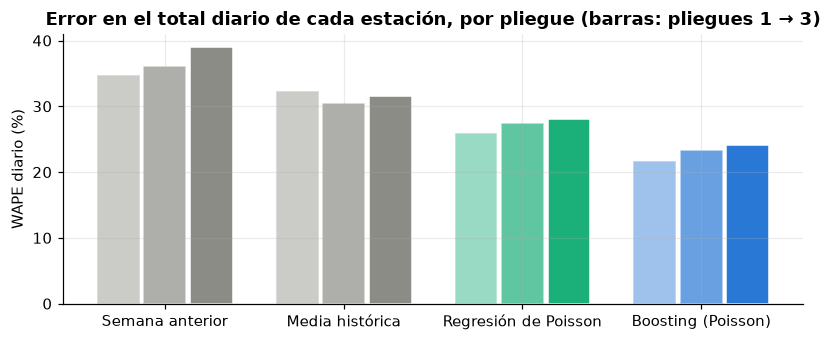

In [12]:
fig, ax = plt.subplots(figsize=(7.5, 3.2))
orden = ["Semana anterior", "Media histórica", "Regresión de Poisson", "Boosting (Poisson)"]
colores = [GRAY, GRAY, AQUA, BLUE]
for i, pliegue in enumerate(sorted(cv.pliegue.unique())):
    valores = cv[cv.pliegue == pliegue].set_index("modelo").loc[orden, "WAPE diario %"]
    ax.bar(np.arange(len(orden)) + (i - 1) * 0.26, valores, width=0.24, color=colores,
           alpha=[0.45, 0.7, 1.0][i], edgecolor="white", linewidth=1)
ax.set_xticks(np.arange(len(orden)), orden)
ax.set_ylabel("WAPE diario (%)")
ax.set_title("Error en el total diario de cada estación, por pliegue (barras: pliegues 1 → 3)")
plt.tight_layout()
plt.show()

**Lectura.** - **El boosting es el mejor en los tres pliegues**, con un margen estable: devianza 1,152 ± 0,051 contra 1,233 de la regresión de Poisson y 1,269 de la media histórica. En el total diario de cada estación el error baja del 31,4 % (media histórica) al **23,0 % ± 1,3**.
- El orden de los modelos es el mismo en todos los pliegues (gráfico), así que la conclusión no depende de la época del año. Como los hiperparámetros se eligieron en otra ventana, estos números no tienen sesgo de selección.
- El **sesgo** de la media histórica cambia mucho entre pliegues (−6,8 % ± 7,3): no sabe en qué estación del año está. El boosting se mantiene cerca de cero (−0,3 % ± 2,1) porque sus rezagos de 7 y 28 días siguen el nivel reciente.

### 8.1 Tratamiento de la demanda censurada

El tercer notebook dejó planteada la pregunta: cuando una estación está **vacía** (`flag_vacia`) o **cerrada** (`sin_alquiler`), los retiros observados son menores que la demanda real. Si el modelo entrena con esas horas, aprende que "a esa hora hay poca demanda" cuando lo que hubo fue poca **oferta**.

Experimento, en el último pliegue: se compara el boosting entrenado con todas las horas contra uno entrenado **sin las horas censuradas**.

**Cuidado: este experimento selecciona por el resultado.** `flag_vacia` se mide en la **misma** hora que el target, y los retiros de esa hora son en parte los que vacían la estación: es la advertencia del tercer notebook. Sacar esas horas del entrenamiento no saca una muestra al azar, saca las horas en que la demanda agotó la oferta. Y evaluar sólo en las horas "limpias" favorece por construcción al modelo que se entrenó con ese mismo tipo de horas. Por eso se miran las dos evaluaciones: sobre todas las horas de validación y sobre las limpias.

In [13]:
censura_retiros = ((df.flag_vacia == 1) | (df.sin_alquiler == 1)).to_numpy()
sin_censura_observada = ((df.flag_vacia == 0) & (df.sin_alquiler == 0)).to_numpy()
print(f"Horas de train censuradas para retiros: {censura_retiros[es_train].mean():.1%} "
      f"(sin fotos, no se sabe: {df.sin_fotos[es_train].mean():.1%})")

boosting_sin_censura = nuevo_boosting().fit(X.loc[entr_val & ~censura_retiros], df.loc[entr_val & ~censura_retiros, "retiros"])
pred_sin_censura = boosting_sin_censura.predict(X.loc[val])

y_val = df.loc[val, "retiros"].to_numpy()
grupos_de_horas = {"Todas las horas": np.ones(val.sum(), dtype=bool),
                   "Horas limpias (con fotos, sin censura)": sin_censura_observada[val],
                   "Horas censuradas": censura_retiros[val]}
filas = []
for horas, mascara in grupos_de_horas.items():
    for modelo, pred in [("con todas las horas", pred_boosting_val), ("sin horas censuradas", pred_sin_censura)]:
        m = metricas(y_val[mascara], pred[mascara])
        filas.append({"evaluado en": horas, "entrenado": modelo, "retiros medios": y_val[mascara].mean(),
                      "predicción media": pred[mascara].mean(), "Devianza Poisson": m["Devianza Poisson"],
                      "Sesgo %": m["Sesgo %"]})
pd.DataFrame(filas).set_index(["evaluado en", "entrenado"]).round(3)

Horas de train censuradas para retiros: 10.2% (sin fotos, no se sabe: 27.2%)


retiros medios  predicción media  Devianza Poisson  Sesgo %
evaluado en                            entrenado                                                                        
Todas las horas                        con todas las horas            0.919             0.931             1.112    1.343
                                       sin horas censuradas           0.919             0.998             1.123    8.669
Horas limpias (con fotos, sin censura) con todas las horas            0.989             0.937             1.127   -5.305
                                       sin horas censuradas           0.989             0.995             1.121    0.557
Horas censuradas                       con todas las horas            0.755             1.086             1.143   43.802
                                       sin horas censuradas           0.755             1.213             1.237   60.563

**Lectura.** - El 10,2 % de las horas de train está censurado (vacía o cerrada) y en otro 27,2 % no se sabe, porque no hay fotos.
- **Sobre todas las horas de validación gana el modelo entrenado con todas las horas:** devianza 1,112 contra 1,123, y sesgo +1,3 % contra +8,7 %.
- **Sobre las horas limpias gana el otro** (1,121 contra 1,127; sesgo +0,6 % contra −5,3 %), pero eso pasa en parte por construcción: se lo evalúa con el mismo tipo de horas con el que se lo entrenó.
- **En las horas censuradas los dos modelos predicen bastante más de lo observado:** 1,09 y 1,21 retiros por hora contra 0,76. Aun el modelo que vio esas horas espera un 44 % más. Son, en general, franjas de mucha demanda en las que la estación se quedó sin bicis. Es evidencia de demanda no atendida, aunque no se pueda medir con precisión.
- **Decisión.** El modelo principal se entrena con **todas las horas**: predice lo que el sistema va a registrar, que es lo que se puede validar de punta a punta, y es el mejor sobre la validación completa. El modelo sin horas censuradas se conserva sólo como **aproximación de la demanda latente** para la sección 12.2, sabiendo que su entrenamiento selecciona horas por el resultado.

## 9. Modelo final y evaluación en test

Se reentrena con **todo el train** (enero de 2024 a mayo de 2026) y se evalúa **una sola vez** en el test (junio a agosto de 2026). Siguiendo la sección 8.1, los dos modelos principales (retiros y arribos) se entrenan con **todas las horas**: predicen los viajes que el sistema va a registrar, que es lo que se puede validar. Aparte se entrena el modelo de retiros **sin horas censuradas**, que se usa sólo como aproximación de la demanda latente en la sección 12.2. El test se evalúa con **todas** sus horas.

In [14]:
inicio = time.perf_counter()
modelo_retiros = nuevo_boosting().fit(X.loc[es_train], df.loc[es_train, "retiros"])
modelo_arribos = nuevo_boosting().fit(X.loc[es_train], df.loc[es_train, "arribos"])
modelo_latente = nuevo_boosting().fit(X.loc[es_train & ~censura_retiros], df.loc[es_train & ~censura_retiros, "retiros"])
glm_retiros = entrenar_glm(es_train, "retiros")
print(f"Modelos finales entrenados en {time.perf_counter() - inicio:.0f} s")

test = df.loc[es_test].copy()
test["pred_retiros"] = modelo_retiros.predict(X.loc[es_test])
test["pred_arribos"] = modelo_arribos.predict(X.loc[es_test])
test["pred_latente"] = modelo_latente.predict(X.loc[es_test])
bases_retiros = predecir_baselines(es_train, es_test, "retiros")
bases_arribos = predecir_baselines(es_train, es_test, "arribos")
test["base_retiros"] = bases_retiros["Media histórica estación × hora × tipo de día"]
test["base_arribos"] = bases_arribos["Media histórica estación × hora × tipo de día"]

resultados_test = {
    "retiros": evaluar(test, test.retiros, {**bases_retiros,
                                             "Regresión de Poisson": glm_retiros.predict(test[COLUMNAS_GLM]),
                                             "Boosting (Poisson)": test.pred_retiros}),
    "arribos": evaluar(test, test.arribos, {**bases_arribos, "Boosting (Poisson)": test.pred_arribos}),
}
pd.concat(resultados_test, names=["target", "modelo"]).round(3)

Modelos finales entrenados en 352 s


Devianza Poisson   RMSE    MAE     R²    RAE  Sesgo %  MAE diario  WAPE diario %
target  modelo                                                                                                                         
retiros Cero                                                     18.218  1.439  0.665 -0.271  0.756 -100.000      15.943        100.000
        Semana anterior                                           7.602  1.385  0.734 -0.178  0.836   -1.595       7.323         45.933
        Promedio 7 días, misma hora                               1.801  1.120  0.681  0.229  0.776   -1.054       7.630         47.855
        Media histórica estación × hora × tipo de día             1.157  1.131  0.734  0.215  0.835   41.526       8.301         52.065
        Regresión de Poisson                                      1.068  1.030  0.641  0.348  0.730   -1.056       5.310         33.304
        Boosting (Poisson)                                        1.009  0.998  0.607  0.389  0.691    0.378       4.630         29.040
arribos Cero                                                     18.193  1.427  0.665 -0.277  0.762 -100.000      15.942        100.000
        Semana anterior                                           7.384  1.345  0.718 -0.135  0.823   -1.598       7.296         45.765
        Promedio 7 días, misma hora                               1.780  1.092  0.670  0.252  0.768   -1.054       7.654         48.009
        Media histórica estación × hora × tipo de día             1.129  1.101  0.721  0.240  0.827   41.442       8.272         51.889
        Boosting (Poisson)                                        0.979  0.967  0.596  0.414  0.683    1.062       4.608         28.902

**Lectura.** - **El boosting es el mejor modelo en test para los dos targets.**
  - Retiros: devianza 1,009 contra 1,068 de la regresión de Poisson y 1,157 de la media histórica; WAPE diario 29,0 % contra 33,3 % y 52,1 %; sesgo +0,4 %.
  - Arribos: devianza 0,979, WAPE diario 28,9 % y sesgo +1,1 %.
- **La media histórica se desploma en test (sesgo +41,5 %).** El test es **invierno**, y la demanda cae fuerte en invierno: 0,66 retiros por estación y hora en el test contra 0,95 de promedio en el train (en junio y julio de 2025 había bajado a 0,52–0,59). La media histórica no conoce la estación del año; el boosting la sigue con los rezagos de 7 y 28 días. Por eso en test hasta copiar la semana anterior le gana en WAPE diario a la media histórica, cosa que no pasaba en la validación.
- **El error en test (WAPE 29 %) es mayor que en la validación cruzada (23 %)** porque con menos viajes el ruido propio de un conteo pesa más en términos relativos. Pasa lo mismo en la ventana de búsqueda, que también es invierno (34 %, con menos datos de entrenamiento).
- **R² = 0,39 por hora es esperable.** Con una media de 0,66 retiros por hora, aunque el modelo conociera la media exacta, el resultado de cada hora sigue siendo aleatorio (en una Poisson la varianza es igual a la media). Las decisiones se toman sobre totales por franja o por día, donde el error relativo es mucho menor.

### 9.1 Modelo principal y modelo latente, por tipo de hora

Se comparan en test el modelo principal (todas las horas) y el entrenado sin horas censuradas, separando las horas según lo que se sabe de la estación.

In [15]:
tipos_de_hora = {
    "Todo el test": np.ones(len(test), dtype=bool),
    "Con bicis (sin censura, con fotos)": sin_censura_observada[es_test],
    "Censuradas (vacía o cerrada)": censura_retiros[es_test],
    "Sin fotos (no se sabe)": test.sin_fotos.eq(1).to_numpy(),
}
filas = []
for tipo, mascara in tipos_de_hora.items():
    sub = test[mascara]
    for modelo, columna in [("principal (todas las horas)", "pred_retiros"), ("latente (sin horas censuradas)", "pred_latente")]:
        filas.append({"horas": tipo, "modelo": modelo, "filas": len(sub), "retiros medios": sub.retiros.mean(),
                      "predicción media": sub[columna].mean(),
                      "sesgo %": 100 * (sub[columna].sum() / sub.retiros.sum() - 1),
                      "devianza": mean_poisson_deviance(sub.retiros, sub[columna])})
pd.DataFrame(filas).set_index(["horas", "modelo"]).round(3)

filas  retiros medios  predicción media  sesgo %  devianza
horas                              modelo                                                                                     
Todo el test                       principal (todas las horas)     870753           0.665             0.667    0.378     1.009
                                   latente (sin horas censuradas)  870753           0.665             0.704    5.959     1.014
Con bicis (sin censura, con fotos) principal (todas las horas)     513534           0.763             0.722   -5.310     1.050
                                   latente (sin horas censuradas)  513534           0.763             0.758   -0.588     1.046
Censuradas (vacía o cerrada)       principal (todas las horas)      82222           0.482             0.758   57.130     1.021
                                   latente (sin horas censuradas)   82222           0.482             0.834   73.003     1.086
Sin fotos (no se sabe)             principal (todas las horas)     274997           0.536             0.537    0.221     0.929
                                   latente (sin horas censuradas)  274997           0.536             0.565    5.315     0.933

**Lectura.** - **El modelo principal no tiene sesgo en el total** (+0,4 %), pero no porque acierte en cada tipo de hora:
  - donde la estación tenía bicis **subestima un 5,3 %**;
  - en las horas censuradas **sobreestima un 57 %**.

  Los dos errores se compensan. Es exactamente lo que se espera de un modelo que aprende los viajes registrados, con la censura incluida.
- **El modelo latente casi no tiene sesgo donde había bicis** (−0,6 %). Donde la estación estaba vacía predice un 73 % más de lo observado: esa diferencia es su estimación de la demanda que no se pudo atender.
- **Son dos preguntas distintas.** Para *cuántos viajes va a registrar el sistema* (el rebalanceo) se usa el modelo principal. Para *cuánta gente quiere usar la estación* (la ampliación) se usa el latente, como aproximación. Se guardan los dos (sección 13).

## 10. Análisis de los resultados

### 10.1 La red completa, hora por hora

Suma de las predicciones de todas las estaciones contra los retiros observados, en dos semanas del test.

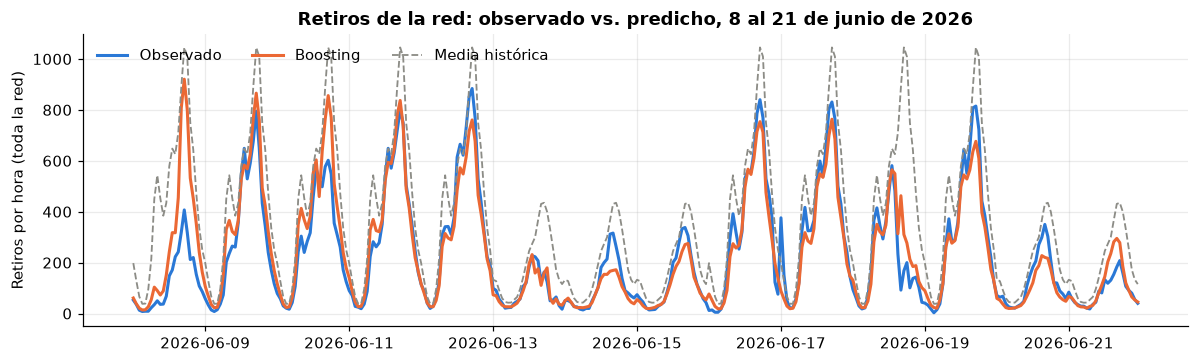

Correlación horaria de la red: boosting 0.941 · media histórica 0.895


In [16]:
red = test.groupby("ts")[["retiros", "pred_retiros", "base_retiros"]].sum()
ventana = red.loc["2026-06-08":"2026-06-21"]

fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(ventana.index, ventana.retiros, color=BLUE, lw=2, label="Observado")
ax.plot(ventana.index, ventana.pred_retiros, color=ORANGE, lw=2, label="Boosting")
ax.plot(ventana.index, ventana.base_retiros, color=GRAY, lw=1.2, ls="--", label="Media histórica")
ax.set_ylabel("Retiros por hora (toda la red)")
ax.set_title("Retiros de la red: observado vs. predicho, 8 al 21 de junio de 2026")
ax.legend(loc="upper left", ncols=3, frameon=False)
plt.tight_layout()
plt.show()
print(f"Correlación horaria de la red: boosting {red.retiros.corr(red.pred_retiros):.3f} · "
      f"media histórica {red.retiros.corr(red.base_retiros):.3f}")

**Lectura.** - A nivel de toda la red el modelo sigue muy bien la forma de cada día (correlación horaria 0,94 contra 0,90 de la media histórica): los dos picos de los días hábiles y la curva única de los fines de semana.
- **El lunes 15/06 fue feriado** (Güemes, trasladado), y el modelo lo predice correctamente como un día de demanda baja.
- **Los errores grandes se concentran en tardes puntuales:** el lunes 8/06 y el viernes 19/06 se registraron muchos menos viajes que los predichos. El modelo no tiene cómo anticiparlo con estas variables. No se verificó la causa (clima de último momento, eventos, cortes).
- La media histórica exagera todos los picos, por el efecto invierno de la sección anterior.

### 10.2 Perfil por hora y sesgo por mes

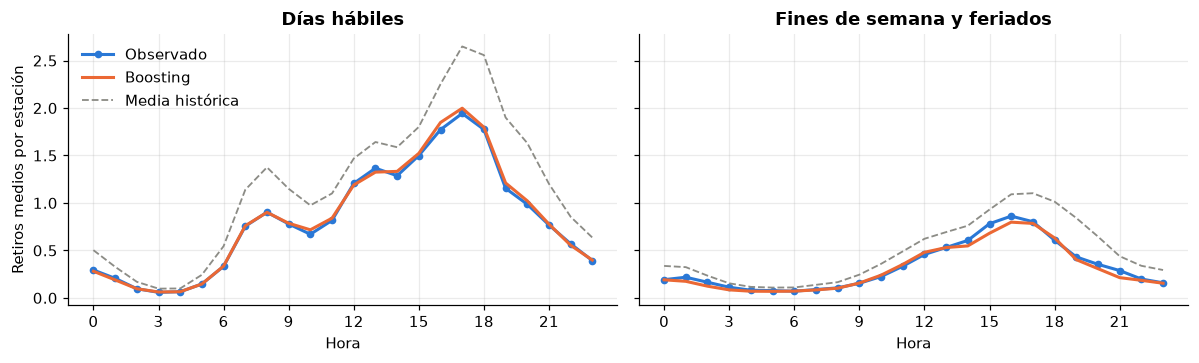

,retiros reales,predichos boosting,sesgo boosting %,sesgo media histórica %,devianza boosting
mes_nombre,,,,,
junio,193254.0,192640.23,-0.32,40.80,0.99
julio,183836.0,185607.33,0.96,50.52,1.03
agosto,201591.0,202618.40,0.51,34.03,1.01


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, (habil, titulo) in zip(axes, [(1, "Días hábiles"), (0, "Fines de semana y feriados")]):
    perfil = test[test.dia_habil == habil].groupby("hora")[["retiros", "pred_retiros", "base_retiros"]].mean()
    ax.plot(perfil.index, perfil.retiros, color=BLUE, lw=2, marker="o", ms=4, label="Observado")
    ax.plot(perfil.index, perfil.pred_retiros, color=ORANGE, lw=2, label="Boosting")
    ax.plot(perfil.index, perfil.base_retiros, color=GRAY, lw=1.2, ls="--", label="Media histórica")
    ax.set_title(titulo)
    ax.set_xlabel("Hora")
    ax.set_xticks(range(0, 24, 3))
axes[0].set_ylabel("Retiros medios por estación")
axes[0].legend(frameon=False)
plt.tight_layout()
plt.show()

test["mes_nombre"] = test.ts.dt.month.map({6: "junio", 7: "julio", 8: "agosto"})
(test.groupby("mes_nombre", sort=False)
     .apply(lambda g: pd.Series({"retiros reales": g.retiros.sum(), "predichos boosting": g.pred_retiros.sum(),
                                 "sesgo boosting %": 100 * (g.pred_retiros.sum() / g.retiros.sum() - 1),
                                 "sesgo media histórica %": 100 * (g.base_retiros.sum() / g.retiros.sum() - 1),
                                 "devianza boosting": mean_poisson_deviance(g.retiros, g.pred_retiros)}),
            include_groups=False)
     .round(2))

**Lectura.** - **Días hábiles:** el modelo reproduce casi exactamente el perfil medio, con los picos de las 8 h y de las 17 h.
- **Fines de semana y feriados:** también ajusta bien, apenas por debajo en el pico de la tarde.
- **Por mes**, el sesgo del boosting está entre −0,3 % y +1,0 %, mientras que el de la media histórica va del +34 % al +51 %.
- Julio es el mes de menos demanda y coincide con las vacaciones de invierno; es justo el mes en que más falla la media histórica.

### 10.3 Calibración

Se agrupan las estación-hora del test en 20 grupos según la predicción y se compara la media predicha con la observada. Un modelo calibrado queda sobre la diagonal: si dice "2 retiros", en promedio hay 2.

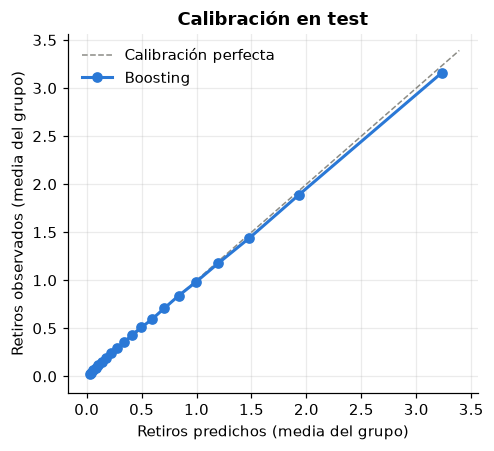

In [18]:
grupos = pd.qcut(test.pred_retiros, 20, duplicates="drop")
calibracion = test.groupby(grupos, observed=True)[["pred_retiros", "retiros"]].mean()

fig, ax = plt.subplots(figsize=(4.6, 4.2))
limite = calibracion.max().max() * 1.05
ax.plot([0, limite], [0, limite], color=GRAY, lw=1, ls="--", label="Calibración perfecta")
ax.plot(calibracion.pred_retiros, calibracion.retiros, color=BLUE, lw=2, marker="o", ms=6, label="Boosting")
ax.set_xlabel("Retiros predichos (media del grupo)")
ax.set_ylabel("Retiros observados (media del grupo)")
ax.set_title("Calibración en test")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

**Lectura.** El modelo está **bien calibrado en todo el rango**: los 20 grupos quedan prácticamente sobre la diagonal, desde las horas casi sin viajes hasta las de más de 3 retiros por hora. En el grupo más alto predice apenas más de lo observado (3,25 contra 3,15). Son las horas pico de las estaciones más usadas, donde la estación a veces se vacía.

### 10.4 Importancia de las variables

Importancia por **permutación** sobre una muestra del test: cuánto empeora la devianza si se mezclan al azar los valores de una variable. A diferencia de la importancia por ganancia de los árboles, se mide sobre datos no vistos y no favorece a las variables con muchos valores distintos.

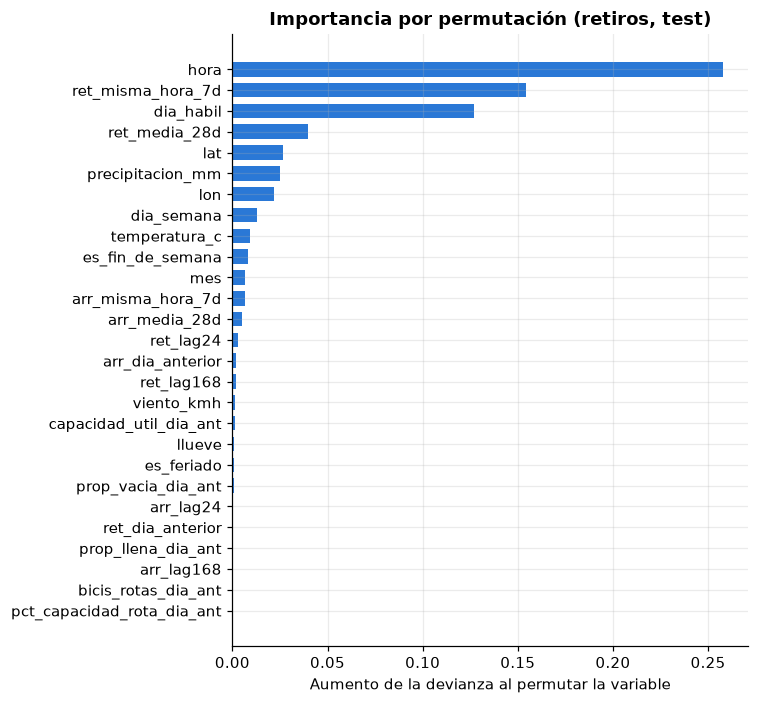

In [19]:
muestra = test.sample(300_000, random_state=SEMILLA)
importancia = permutation_importance(modelo_retiros, muestra[VARIABLES], muestra.retiros,
                                     scoring="neg_mean_poisson_deviance", n_repeats=3,
                                     random_state=SEMILLA, n_jobs=1)
importancia = pd.Series(importancia.importances_mean, index=VARIABLES).sort_values()

fig, ax = plt.subplots(figsize=(7, 6.5))
ax.barh(importancia.index, importancia.values, color=BLUE, height=0.7)
ax.set_xlabel("Aumento de la devianza al permutar la variable")
ax.set_title("Importancia por permutación (retiros, test)")
plt.tight_layout()
plt.show()

**Lectura.** - **La hora es por lejos la variable más importante.** Le siguen el promedio de la **misma hora en la última semana** y si es **día hábil**. Después vienen el **nivel de la estación** (`ret_media_28d`), la **ubicación** y la **lluvia**.
- **Los rezagos puntuales** (`ret_lag24`, `ret_lag168`) importan poco: el promedio de 7 días contiene la misma información con menos ruido. Lo mismo pasa con `llueve` frente a `precipitacion_mm`. Con variables correlacionadas, la permutación reparte la importancia entre ellas (al mezclar una, la otra la sigue cubriendo).
- **`mes` pesa poco** porque la estacionalidad ya entra por los rezagos.
- **Las variables de estado de la estación (fotos) no aportan.** Puede que su información ya esté en los rezagos de demanda, o que el promedio del día anterior sea demasiado grueso, porque lo que vacía una estación pasa hora a hora. Además faltan en el 21–44 % del test. Para un horizonte más corto (la hora siguiente) probablemente sí servirían.

### 10.5 Error por estación

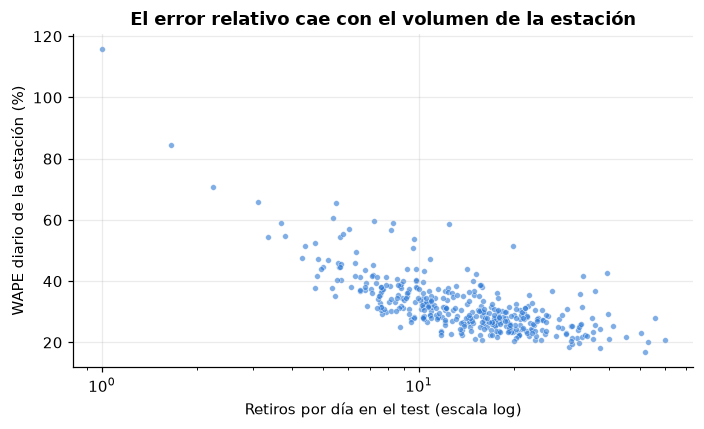

Estaciones con más de 20 retiros por día, peor error relativo:


,retiros_por_dia,pred_por_dia,mae_diario,wape_%,nombre
station_id,,,,,
515,39.2,38.1,16.8,42.8,294 - PLAZOLETA RÍO DE LA PLATA
379,33.0,32.6,13.8,41.7,390 - De Los Ombues
156,26.3,25.2,9.7,36.9,156 - Plaza Alemania
152,36.0,34.1,13.3,36.8,152 - JULIETA LANTERI
161,32.3,31.0,11.6,35.9,161 - Humahuaca
177,22.3,22.0,8.0,35.6,177 -PLANETARIO
281,22.8,22.6,7.5,32.7,350 - Plaza Irlanda
137,20.2,20.6,6.6,32.6,137 - AZOPARDO Y CHILE


In [20]:
estaciones = pd.read_csv(PROCESSED_DIR / "estaciones.csv").set_index("station_id")
diario = (test.assign(fecha=test.ts.dt.floor("D"))
              .groupby(["station_id", "fecha"])[["retiros", "pred_retiros"]].sum())
por_estacion = (diario.assign(error=(diario.pred_retiros - diario.retiros).abs())
                      .groupby("station_id")
                      .agg(retiros_por_dia=("retiros", "mean"), pred_por_dia=("pred_retiros", "mean"),
                           mae_diario=("error", "mean")))
por_estacion["wape_%"] = 100 * por_estacion.mae_diario / por_estacion.retiros_por_dia.replace(0, np.nan)
por_estacion = por_estacion.join(estaciones.nombre)

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.scatter(por_estacion.retiros_por_dia, por_estacion["wape_%"], s=14, color=BLUE, alpha=0.6, edgecolor="white", lw=0.4)
ax.set_xscale("log")
ax.set_xlabel("Retiros por día en el test (escala log)")
ax.set_ylabel("WAPE diario de la estación (%)")
ax.set_title("El error relativo cae con el volumen de la estación")
plt.tight_layout()
plt.show()
print("Estaciones con más de 20 retiros por día, peor error relativo:")
por_estacion[por_estacion.retiros_por_dia > 20].sort_values("wape_%", ascending=False).head(8).round(1)

**Lectura.** - El error relativo **cae con el volumen**: más del 50 % en estaciones con menos de 5 retiros por día y entre 20 y 30 % en las de más de 20. Es lo esperable con conteos: el ruido relativo de una Poisson baja como $1/\sqrt{n}$.
- **Entre las estaciones de mucho uso, las peores son recreativas:**
  - Plazoleta Río de la Plata (Costanera);
  - De los Ombúes, Plaza Alemania, Planetario y Plaza Irlanda (parques);
  - Julieta Lanteri (Costanera Sur).

  Su demanda depende del fin de semana, del sol y de eventos, y es mucho más volátil que la de las estaciones de viaje al trabajo.

## 11. Agrupamiento de estaciones (aprendizaje no supervisado)

Las estaciones no se usan igual: unas son **origen** a la mañana (barrios residenciales, la gente sale a trabajar) y **destino** a la tarde, y otras al revés. Para el rebalanceo importa saber **a qué hora** se vacía o se llena cada una.

**Perfil de cada estación:** para los días hábiles del último año del train (junio de 2025 a mayo de 2026), la fracción de sus movimientos diarios (retiros + arribos) que ocurre en cada hora, separada en retiros y arribos: 48 valores que suman 1. Así se compara la **forma** del día y no el volumen. Se dejan afuera las estaciones con menos de 5 movimientos por día hábil, cuyo perfil es puro ruido.

**Técnica:** *K-means*. Las variables ya están en la misma escala (proporciones), así que no se estandarizan: estandarizar inflaría el ruido de las horas de la madrugada. DBSCAN no aplica bien acá: en 48 dimensiones la densidad no separa grupos y además dejaría estaciones como "ruido", cuando cada estación necesita un grupo.

Estaciones con perfil: 404 de 405


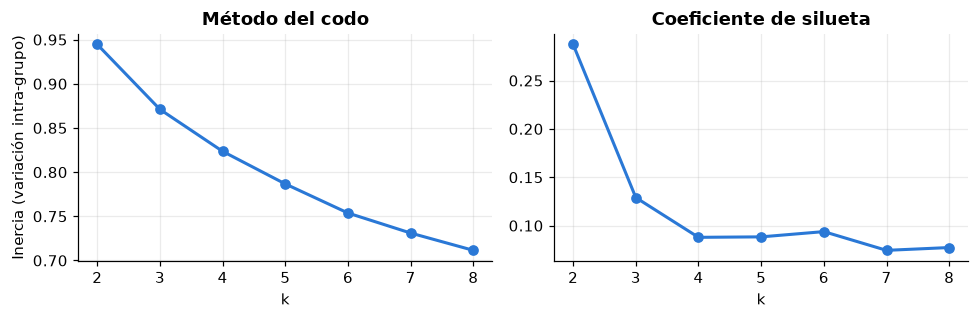

,2,3,4,5,6,7,8
inercia,0.945,0.871,0.824,0.787,0.754,0.731,0.711
silueta,0.287,0.129,0.088,0.088,0.094,0.074,0.077


In [21]:
ultimo_anio = es_train & (df.ts >= "2025-06-01").to_numpy() & (df.dia_habil == 1).to_numpy()
perfil = df.loc[ultimo_anio].groupby(["station_id", "hora"])[["retiros", "arribos"]].mean().unstack("hora")
movimientos_dia = perfil.sum(axis=1)
perfil = perfil[movimientos_dia >= 5]
forma = perfil.div(perfil.sum(axis=1), axis=0)
forma.columns = [f"{tipo}_{hora:02d}" for tipo, hora in forma.columns]
print(f"Estaciones con perfil: {len(forma)} de {len(movimientos_dia)}")

ks = range(2, 9)
modelos_k = {k: KMeans(n_clusters=k, n_init=20, random_state=SEMILLA).fit(forma) for k in ks}
eleccion_k = pd.DataFrame({"inercia": {k: m.inertia_ for k, m in modelos_k.items()},
                           "silueta": {k: silhouette_score(forma, m.labels_) for k, m in modelos_k.items()}})

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].plot(eleccion_k.index, eleccion_k.inercia, color=BLUE, lw=2, marker="o", ms=6)
axes[0].set_title("Método del codo")
axes[0].set_ylabel("Inercia (variación intra-grupo)")
axes[1].plot(eleccion_k.index, eleccion_k.silueta, color=BLUE, lw=2, marker="o", ms=6)
axes[1].set_title("Coeficiente de silueta")
for ax in axes:
    ax.set_xlabel("k")
plt.tight_layout()
plt.show()
eleccion_k.round(3).T

**Lectura.** - **La silueta es baja para todo k** (0,29 con k = 2 y entre 0,07 y 0,13 desde k = 3), y la inercia baja de forma suave, sin codo claro. Los perfiles horarios forman un **continuo**, no grupos bien separados: hay estaciones de todos los grados intermedios entre "origen a la mañana" y "destino a la mañana".
- Por eso k no se elige por la silueta (que favorece dos grupos, demasiado gruesos para operar) sino por **interpretabilidad**. Con **k = 4** aparecen cuatro patrones distintos y con sentido operativo (gráficos de abajo). El agrupamiento se usa como **segmentación descriptiva**, no como clases naturales.
- Las etiquetas de K-means son arbitrarias. Por eso los nombres de los grupos se asignan en el código a partir del flujo neto de la mañana de cada centroide, y siguen siendo correctos si se reentrena.

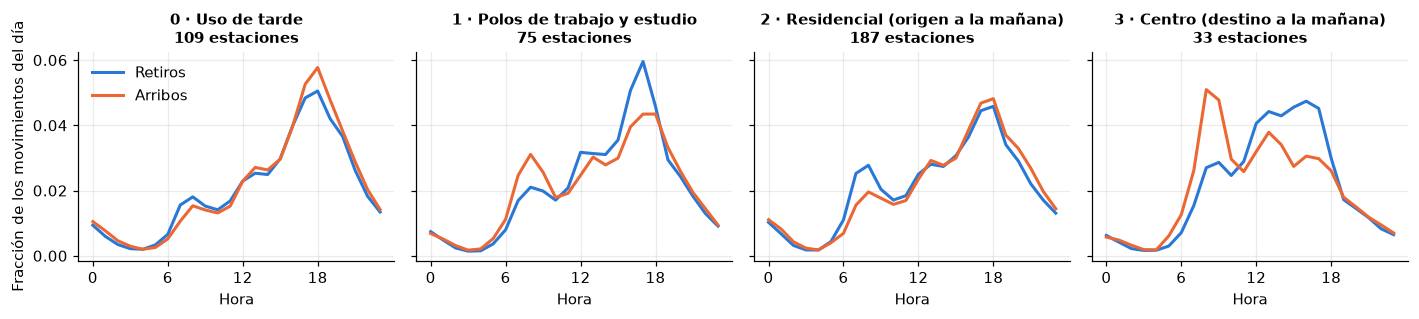

grupo,0,1,2,3
hora (flujo neto medio),,,,
7,-0.16,0.37,-0.52,0.66
8,-0.07,0.52,-0.44,1.20
9,-0.04,0.28,-0.14,0.95
17,0.16,-0.71,0.13,-0.76
18,0.27,-0.11,0.10,-0.14
19,0.21,0.15,0.13,0.02


In [22]:
K = 4  # ver la lectura anterior: se elige por interpretabilidad, no por la silueta
kmeans = modelos_k[K]
# Las etiquetas de K-means son arbitrarias: los nombres se asignan según el flujo neto de la mañana (7 a 9 h)
# de cada centroide, para que sigan siendo correctos si se reentrena con otros datos.
centroides = pd.DataFrame(kmeans.cluster_centers_, columns=forma.columns)
neto_manana = (centroides[[f"arribos_{h:02d}" for h in (7, 8, 9)]].sum(axis=1).to_numpy()
               - centroides[[f"retiros_{h:02d}" for h in (7, 8, 9)]].sum(axis=1).to_numpy())
orden = np.argsort(-neto_manana)  # del más "destino" al más "origen" a la mañana
NOMBRES_GRUPOS = {int(orden[0]): "Centro (destino a la mañana)",
                  int(orden[1]): "Polos de trabajo y estudio",
                  int(orden[2]): "Uso de tarde",
                  int(orden[3]): "Residencial (origen a la mañana)"}
grupo = pd.Series(kmeans.labels_, index=forma.index, name="grupo")
# Flujo neto medio por hora de cada grupo, en viajes por estación (no en proporción)
neto = (perfil["arribos"] - perfil["retiros"]).groupby(grupo).mean()

fig, axes = plt.subplots(1, K, figsize=(13, 3), sharey=True)
for g, ax in enumerate(axes):
    centroide = pd.Series(kmeans.cluster_centers_[g], index=forma.columns)
    ax.plot(range(24), centroide.filter(like="retiros").values, color=BLUE, lw=2, label="Retiros")
    ax.plot(range(24), centroide.filter(like="arribos").values, color=ORANGE, lw=2, label="Arribos")
    ax.set_title(f"{g} · {NOMBRES_GRUPOS[g]}\n{(grupo == g).sum()} estaciones", fontsize=10)
    ax.set_xticks(range(0, 24, 6))
    ax.set_xlabel("Hora")
axes[0].set_ylabel("Fracción de los movimientos del día")
axes[0].legend(frameon=False)
plt.tight_layout()
plt.show()
neto.round(2).T.loc[[7, 8, 9, 17, 18, 19]].rename_axis("hora (flujo neto medio)")

**Lectura.** | Grupo | Patrón | Flujo neto a las 8 h / 17 h (viajes por estación) |
|---|---|---|
| **Centro (destino a la mañana)** | 33 estaciones, concentradas en el centro y el este de la ciudad. Los arribos tienen un pico marcado a las 8–9 h y los retiros se reparten entre el mediodía y las 17 h | **+1,20** / −0,76: se **llena** a la mañana y se **vacía** a la tarde |
| **Polos de trabajo y estudio** | 75 estaciones dispersas, más al norte. El mismo patrón que el centro pero más suave, con el pico de retiros a las 17 h | +0,52 / −0,71 |
| **Residencial (origen a la mañana)** | 187 estaciones, el cinturón central y oeste. Salen más bicis de las que llegan a las 7–9 h, y vuelven a la tarde | **−0,52** (a las 7 h) / +0,13: se **vacía** a la mañana |
| **Uso de tarde** | 109 estaciones, sobre todo en la periferia. Poco movimiento a la mañana, casi todo entre las 15 y las 20 h, y equilibrado | ≈ 0 / +0,16 |

**Para el rebalanceo:** a la mañana las estaciones residenciales se quedan sin bicis y las del centro sin lugar. El movimiento natural de los camiones es **del centro a los barrios** durante la mañana, y al revés a la tarde.

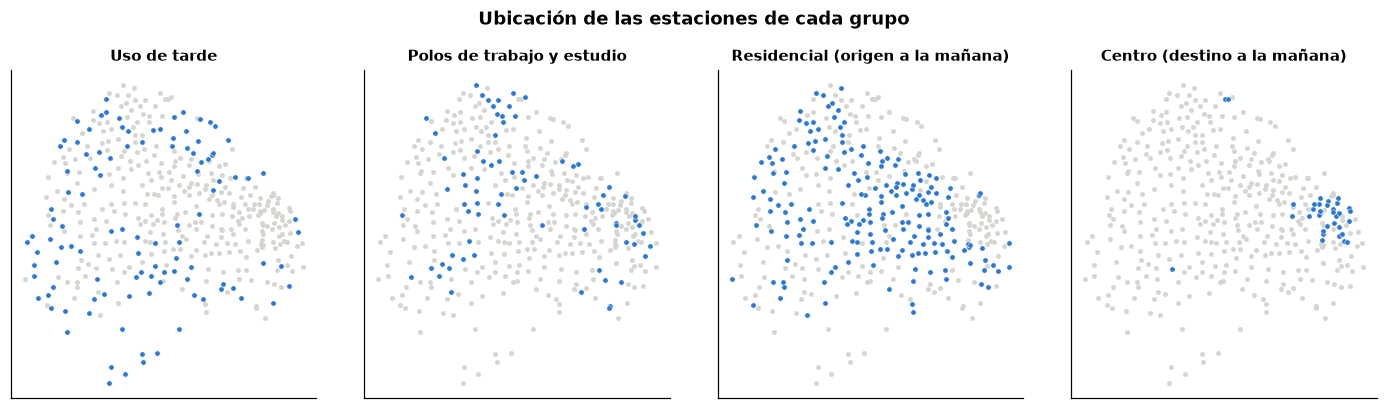

,estaciones,retiros por estación y día,WAPE boosting %,WAPE media histórica %
grupo,,,,
Centro (destino a la mañana),32.0,15.1,30.6,59.8
Polos de trabajo y estudio,73.0,15.9,28.4,49.5
Residencial (origen a la mañana),185.0,16.8,27.4,50.4
Uso de tarde,104.0,14.9,32.3,54.8
poco uso (sin perfil),2.0,5.6,48.9,61.5


In [23]:
ubicacion = estaciones.join(grupo, how="inner")

fig, axes = plt.subplots(1, K, figsize=(13, 3.6), sharex=True, sharey=True)
for g, ax in enumerate(axes):
    ax.scatter(estaciones.lon, estaciones.lat, s=5, color="#d6d6d1")
    sub = ubicacion[ubicacion.grupo == g]
    ax.scatter(sub.lon, sub.lat, s=12, color=BLUE, edgecolor="white", lw=0.3)
    ax.set_title(NOMBRES_GRUPOS[g], fontsize=10)
    ax.set_aspect(1 / np.cos(np.radians(-34.6)))
    ax.set_xticks([])
    ax.set_yticks([])
plt.suptitle("Ubicación de las estaciones de cada grupo", fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

test_grupo = test.join(grupo, on="station_id")
test_grupo["grupo"] = test_grupo.grupo.map(NOMBRES_GRUPOS).fillna("poco uso (sin perfil)")
diario_grupo = (test_grupo.assign(fecha=test_grupo.ts.dt.floor("D"))
                          .groupby(["grupo", "station_id", "fecha"])[["retiros", "pred_retiros", "base_retiros"]].sum())
(diario_grupo.groupby("grupo")
             .apply(lambda g: pd.Series({"estaciones": g.index.get_level_values("station_id").nunique(),
                                         "retiros por estación y día": g.retiros.mean(),
                                         "WAPE boosting %": 100 * (g.pred_retiros - g.retiros).abs().sum() / g.retiros.sum(),
                                         "WAPE media histórica %": 100 * (g.base_retiros - g.retiros).abs().sum() / g.retiros.sum()}))
             .round(1))

**Lectura.** El boosting reduce el error a casi la mitad del de la media histórica en todos los grupos (WAPE de 27 a 32 % contra 50 a 60 %). Los grupos más difíciles son el de **uso de tarde** (32,3 %), con más uso recreativo y más dependiente del clima, y el **centro** (30,6 %), con los flujos más concentrados.

## 12. Uso de la solución: rebalanceo y ampliación

### 12.1 ¿Qué estaciones se van a vaciar o llenar?

Para cada día hábil del test y cada franja pico se calcula el **flujo neto predicho** de cada estación (arribos − retiros predichos, sumados en la franja). Las 15 con el flujo más negativo son las que hay que **abastecer** antes de la franja; las 15 con el flujo más positivo, las que hay que **descargar**. Se compara con las 15 reales de ese día:

- **Precisión@15:** de las 15 que señala el modelo, cuántas están entre las 15 reales.
- **Spearman:** correlación de rangos entre el flujo neto predicho y el real, sobre todas las estaciones.

In [24]:
FRANJAS = {"mañana (6 a 9 h)": range(6, 10), "tarde (16 a 19 h)": range(16, 20)}
TOP = 15
habiles = test[test.dia_habil == 1].assign(fecha=lambda d: d.ts.dt.floor("D"))


def flujo_neto(horas):
    return (habiles[habiles.hora.isin(horas)]
            .assign(real=lambda d: d.arribos - d.retiros,
                    boosting=lambda d: d.pred_arribos - d.pred_retiros,
                    media_historica=lambda d: d.base_arribos - d.base_retiros)
            .groupby(["fecha", "station_id"])[["real", "boosting", "media_historica"]].sum())


def precision_top(dia, columna, signo):
    reales = set((signo * dia.real).nlargest(TOP).index)
    predichas = set((signo * dia[columna]).nlargest(TOP).index)
    return len(reales & predichas) / TOP


filas = []
for franja, horas in FRANJAS.items():
    for fecha, dia in flujo_neto(horas).groupby(level="fecha"):
        dia = dia.droplevel("fecha")
        for columna in ["boosting", "media_historica"]:
            filas.append({"franja": franja, "modelo": columna, "fecha": fecha,
                          "precisión@15 abastecer": precision_top(dia, columna, -1),
                          "precisión@15 descargar": precision_top(dia, columna, 1),
                          "Spearman": spearmanr(dia.real, dia[columna]).statistic})
rebalanceo = pd.DataFrame(filas)
rebalanceo.groupby(["franja", "modelo"])[["precisión@15 abastecer", "precisión@15 descargar", "Spearman"]].mean().round(3)

precisión@15 abastecer  precisión@15 descargar  Spearman
franja            modelo                                                                   
mañana (6 a 9 h)  boosting                          0.376                   0.497     0.506
                  media_historica                   0.392                   0.445     0.474
tarde (16 a 19 h) boosting                          0.275                   0.277     0.293
                  media_historica                   0.289                   0.283     0.287

**Lectura.** - **A la mañana**, de las 15 estaciones que el modelo señala para **descargar**, la mitad (50 %) están entre las 15 que efectivamente más se llenaron. Para **abastecer** acierta el 38 %. La correlación de rangos con el flujo real es de 0,51. Elegir 15 estaciones al azar entre ~400 acertaría un 4 %.
- **A la tarde** el rendimiento cae (28 %, Spearman 0,29): los flujos de la tarde están más repartidos entre estaciones y dependen más de cada día.
- **Resultado importante: para ordenar estaciones, el boosting apenas se diferencia de la media histórica.** Es mejor para descargar a la mañana (0,50 contra 0,45) y en Spearman (0,51 contra 0,47), pero algo peor para abastecer (0,38 contra 0,39 a la mañana, 0,28 contra 0,29 a la tarde). Hay tres razones:
  1. **Qué estación se vacía es bastante estructural** (residencial a la mañana, centro a la tarde), y la media histórica lo estima con dos años y medio de datos. Su sesgo de nivel del invierno no la perjudica para *ordenar*, porque afecta a todas las estaciones por igual.
  2. El modelo optimiza la devianza **de cada target por separado, hora por hora**, no la **diferencia** arribos − retiros sumada en la franja: los errores de los dos modelos se suman.
  3. El flujo real está **censurado**: una estación vacía no puede registrar más retiros, y eso achica justamente los flujos que se quieren detectar.

  El boosting sigue siendo mucho mejor para estimar **cuántas** bicis mover (WAPE diario 29 % contra 52 %). Las mejoras para la parte de orden están en la sección 14.

**Ejemplo de salida operativa:** la lista que recibiría el equipo de logística para la mañana del martes 2 de junio de 2026.

In [25]:
ejemplo = flujo_neto(FRANJAS["mañana (6 a 9 h)"]).loc[pd.Timestamp("2026-06-02")].join(estaciones.nombre)
columnas = {"nombre": "estación", "boosting": "flujo neto predicho", "real": "flujo neto real"}
abastecer = ejemplo.nsmallest(10, "boosting")[list(columnas)].rename(columns=columnas)
descargar = ejemplo.nlargest(10, "boosting")[list(columnas)].rename(columns=columnas)
pd.concat({"Abastecer (se vacían)": abastecer.reset_index(drop=True),
           "Descargar (se llenan)": descargar.reset_index(drop=True)}, axis=1).round(1)

Abastecer (se vacían)                                                 Descargar (se llenan)                                    
                       estación flujo neto predicho flujo neto real                          estación flujo neto predicho flujo neto real
0            147 - Constitución               -19.0             -37               026 - JUANA MANSO I                19.4              19
1               130 - RETIRO II               -17.1             -21             035 - INGENIERO BUTTY                13.1               2
2                002 - Retiro I                -9.7             -10               237 - Madero Office                12.1              21
3                014 - Pacifico                -9.6               3              111 - MACACHA GUEMES                11.1              12
4           115 - JUAN DE GARAY                -5.8              -1  227 -Club Ciudad de Buenos Aires                10.0               5
5           276 - PRIMERA JUNTA                -5.2              -5        344 - UNIVERSIDAD DI TELLA                 9.4               8
6                    013 - ONCE                -5.0              -3            137 - AZOPARDO Y CHILE                 7.2               0
7                 163 - ONCE II                -5.0              -5                       036 - MAIPÚ                 5.8               1
8  169 - FACULTAD DE PSICOLOGIA                -4.6              -2                       214 - MORÓN                 5.6               9
9        104 - Federico Lacroze                -4.4              -3         131- HOSPITAL DE CLÍNICAS                 5.6               6

### 12.2 ¿Qué estaciones conviene ampliar?

Una estación es candidata a ampliarse cuando **pierde demanda por falta de capacidad**: se queda sin bicis (o sin lugar) seguido y, cuando eso pasa, había gente que la iba a usar. Para estimar esa demanda perdida se usa el modelo **entrenado sin horas censuradas** (sección 8.1): una **aproximación** de cuántos retiros habría habido si la estación hubiera tenido bicis. Es una aproximación porque ese modelo se entrenó seleccionando horas por el resultado (sección 8.1). Sirve para **ordenar** estaciones, pero los totales hay que leerlos como un orden de magnitud. En las horas en que la estación estuvo vacía o cerrada:

$$\text{retiros perdidos} = \max(0,\ \text{predicción sin censura} - \text{retiros observados})$$

Se calcula sobre el test, sólo con las horas que tienen fotos (sin fotos no se sabe si la estación estaba vacía).

In [26]:
con_fotos = test[test.sin_fotos == 0].copy()
censurada = (con_fotos.flag_vacia == 1) | (con_fotos.sin_alquiler == 1)
con_fotos["perdidos"] = np.where(censurada, (con_fotos.pred_latente - con_fotos.retiros).clip(lower=0), 0)
dias = con_fotos.assign(fecha=con_fotos.ts.dt.floor("D")).groupby("station_id").fecha.nunique()

ampliacion = (con_fotos.groupby("station_id")
                       .agg(capacidad=("capacidad_publicada", "median"),
                            retiros=("retiros", "sum"), arribos=("arribos", "sum"),
                            perdidos=("perdidos", "sum"),
                            pct_horas_vacia=("flag_vacia", "mean"),
                            pct_horas_llena_por_rotas=("flag_llena_por_rotas", "mean")))
ampliacion["retiros_por_dia"] = ampliacion.retiros / dias
ampliacion["perdidos_por_dia"] = ampliacion.perdidos / dias
ampliacion["movimientos_por_anclaje"] = (ampliacion.retiros + ampliacion.arribos) / dias / ampliacion.capacidad.replace(0, np.nan)
ampliacion["pct_demanda_perdida"] = 100 * ampliacion.perdidos / (ampliacion.retiros + ampliacion.perdidos)
ampliacion[["pct_horas_vacia", "pct_horas_llena_por_rotas"]] *= 100
ampliacion = ampliacion.join(estaciones.nombre).join(grupo.map(NOMBRES_GRUPOS))

print(f"Retiros perdidos estimados en el test (horas con fotos): {ampliacion.perdidos.sum():,.0f} "
      f"({100 * ampliacion.perdidos.sum() / (ampliacion.retiros.sum() + ampliacion.perdidos.sum()):.1f} % de la demanda)")
(ampliacion.sort_values("perdidos_por_dia", ascending=False)
           [["nombre", "grupo", "capacidad", "retiros_por_dia", "perdidos_por_dia", "pct_demanda_perdida",
             "pct_horas_vacia", "pct_horas_llena_por_rotas", "movimientos_por_anclaje"]]
           .head(15).round(1))

Retiros perdidos estimados en el test (horas con fotos): 41,552 (8.8 % de la demanda)


,nombre,grupo,capacidad,retiros_por_dia,perdidos_por_dia,pct_demanda_perdida,pct_horas_vacia,pct_horas_llena_por_rotas,movimientos_por_anclaje
station_id,,,,,,,,,
32,032 - Catedral,Centro (destino a la mañana),18.0,14.0,4.6,24.9,54.200001,0.0,1.5
444,061 - Ministerio de Economia,Centro (destino a la mañana),24.0,16.1,4.6,22.3,48.500000,0.0,1.3
71,071 - CERRITO,Centro (destino a la mañana),30.0,15.7,4.4,22.1,38.200001,0.0,1.0
33,033 - Facultad de Medicina,Centro (destino a la mañana),20.0,15.3,4.4,22.4,40.400002,0.0,1.5
131,131- HOSPITAL DE CLÍNICAS,Polos de trabajo y estudio,16.0,27.9,4.3,13.2,30.400000,0.6,3.4
14,014 - Pacifico,Residencial (origen a la mañana),30.0,43.9,4.2,8.7,15.800000,0.0,2.9
4,004 - Plaza Roma,Polos de trabajo y estudio,20.0,23.2,4.1,15.0,35.000000,0.0,2.4
111,111 - MACACHA GUEMES,Centro (destino a la mañana),30.0,16.6,3.9,18.9,36.700001,0.0,1.1
85,085 - AGUERO,Residencial (origen a la mañana),20.0,15.7,3.7,19.0,36.700001,0.0,1.6


**Lectura.** - En las horas del test con fotos se estiman **~41.600 retiros perdidos** por falta de bicis o por estación cerrada, alrededor del **9 % de la demanda**. Es un orden de magnitud, no una medición (ver arriba).
- **Las candidatas son, sobre todo, estaciones del centro** (Catedral, Ministerio de Economía, Cerrito, Facultad de Medicina, Aduana, Macacha Güemes): están vacías entre el 37 y el 54 % de las horas y pierden entre el 18 y el 25 % de su demanda. Acá el problema **no es la cantidad de anclajes sino de bicis**: se llenan a la mañana, se vacían a la tarde y casi nunca están llenas por bicis rotas. Para ellas la primera respuesta es **rebalancear** (traer bicis a la tarde), no ampliar.
- **Las candidatas a ampliar de verdad son las de alta rotación:** Hospital de Clínicas (3,4 movimientos por anclaje y por día, 16 anclajes), Plaza Roma y Pacífico (44 retiros por día). Pierden demanda aunque se usan intensamente: más anclajes, y más bicis, les permitirían atender más viajes.
- **Límites:**
  - el modelo latente se entrenó seleccionando horas por el resultado;
  - es sólo invierno;
  - deja afuera las horas sin fotos (21–44 % del test);
  - tampoco incluye los arribos perdidos por estación llena.

## 13. Persistencia

Se guarda todo lo necesario para predecir **sin reentrenar**:

| Archivo | Contenido |
|---|---|
| `hgb_retiros.joblib`, `hgb_arribos.joblib` | Modelos principales de boosting (todas las horas) |
| `hgb_retiros_latente.joblib` | Modelo sin horas censuradas: aproximación de la demanda latente, para la sección 12.2 |
| `glm_retiros.joblib` | Regresión de Poisson (pipeline completo con su preprocesamiento), como referencia interpretable |
| `kmeans_perfiles.joblib` | *K-means* de perfiles horarios |
| `grupos_estaciones.csv` | Grupo asignado a cada estación |
| `metadata.json` | Variables, hiperparámetros, período de entrenamiento, métricas de test, versiones y la **consulta SQL** que arma las variables |

Se usa `joblib` porque es el formato recomendado por scikit-learn para sus modelos. La consulta va en el `metadata.json` porque el modelo sólo sirve si las variables se construyen igual que al entrenar.

In [27]:
artefactos = {
    "hgb_retiros.joblib": modelo_retiros,
    "hgb_arribos.joblib": modelo_arribos,
    "hgb_retiros_latente.joblib": modelo_latente,
    "glm_retiros.joblib": glm_retiros,
    "kmeans_perfiles.joblib": kmeans,
}
for viejo in MODELS_DIR.glob("*.joblib"):  # que no queden modelos de corridas anteriores
    viejo.unlink()
for nombre, objeto in artefactos.items():
    joblib.dump(objeto, MODELS_DIR / nombre, compress=3)
(grupo.to_frame().assign(nombre_grupo=grupo.map(NOMBRES_GRUPOS)).join(estaciones.nombre)
      .to_csv(MODELS_DIR / "grupos_estaciones.csv"))

metadata = {
    "descripcion": "Demanda horaria de Ecobici por estación, para el día siguiente",
    "horizonte": "24 horas del día D, con información disponible al cierre del día D-1",
    "entrenado": pd.Timestamp.now().isoformat(timespec="seconds"),
    "periodo_entrenamiento": [str(df.loc[es_train, "ts"].min()), str(df.loc[es_train, "ts"].max())],
    "variables": VARIABLES,
    "columnas_glm": COLUMNAS_GLM,
    "hiperparametros": HIPERPARAMETROS,
    "ventana_busqueda": [str(BUSQUEDA[0]), str(BUSQUEDA[1])],
    "modelo_latente": "hgb_retiros_latente.joblib, entrenado sin horas con flag_vacia o sin_alquiler",
    "grupos": {str(k): v for k, v in NOMBRES_GRUPOS.items()},
    "metricas_test": {target: tabla.loc["Boosting (Poisson)"].round(4).to_dict()
                      for target, tabla in resultados_test.items()},
    "versiones": {"python": __import__("platform").python_version(), "scikit-learn": sklearn.__version__,
                  "pandas": pd.__version__, "duckdb": duckdb.__version__},
    "consulta_variables": CONSULTA_VARIABLES,
}
(MODELS_DIR / "metadata.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2, default=str))

pd.DataFrame([{"archivo": ruta.relative_to(REPO_DIR).as_posix(), "MB": round(ruta.stat().st_size / 1e6, 2)}
              for ruta in sorted(MODELS_DIR.iterdir())])

,archivo,MB
0,models/glm_retiros.joblib,0.00
1,models/grupos_estaciones.csv,0.02
2,models/hgb_arribos.joblib,2.86
3,models/hgb_retiros.joblib,2.86
4,models/hgb_retiros_latente.joblib,2.86
5,models/kmeans_perfiles.joblib,0.00
6,models/metadata.json,0.01


**Control: cargar y predecir sin reentrenar.** La función de abajo usa **sólo** los archivos de `models/` y el dataset procesado: lee la consulta del `metadata.json`, arma las variables con los 29 días previos y predice un día completo.

**Alcance:** sirve para días que ya están en el dataset (*backtest*), porque toma el calendario y el clima de la grilla del tercer notebook. Para predecir **mañana** de verdad hay que agregar la grilla del día siguiente con su calendario y el **pronóstico** del clima. Es la integración que queda para el próximo entregable: el modelo y la construcción de variables no cambian.

In [28]:
def predecir_dia(fecha, dir_modelos=MODELS_DIR, fuente=DATASET):
    meta = json.loads((dir_modelos / "metadata.json").read_text())
    modelo_ret = joblib.load(dir_modelos / "hgb_retiros.joblib")
    modelo_arr = joblib.load(dir_modelos / "hgb_arribos.joblib")
    inicio = pd.Timestamp(fecha)
    desde = (inicio - pd.Timedelta(days=29)).strftime("%Y-%m-%d")  # la ventana más larga es de 28 días
    consulta = meta["consulta_variables"].format(fuente=Path(fuente).as_posix(), desde=desde)
    # Las ventanas se calculan sobre los 29 días previos y recién después se filtra el día
    conexion = duckdb.connect()
    conexion.execute("SET enable_progress_bar = false")
    datos = conexion.execute(
        f"SELECT * FROM ({consulta}) WHERE ts >= ? AND ts < ?",
        [inicio.to_pydatetime(), (inicio + pd.Timedelta(days=1)).to_pydatetime()],
    ).df()
    datos["pred_retiros"] = modelo_ret.predict(datos[meta["variables"]])
    datos["pred_arribos"] = modelo_arr.predict(datos[meta["variables"]])
    return datos[["station_id", "ts", "pred_retiros", "pred_arribos", "retiros", "arribos"]]


inicio = time.perf_counter()
dia = predecir_dia("2026-06-02")
print(f"Predicción del 02/06/2026 desde los archivos: {len(dia):,} estación-hora en {time.perf_counter() - inicio:.0f} s")
en_memoria = test.loc[test.ts.dt.floor("D") == "2026-06-02", ["station_id", "ts", "pred_retiros", "pred_arribos"]]
comparacion = dia.merge(en_memoria, on=["station_id", "ts"], suffixes=("", "_memoria"))
assert len(comparacion) == len(dia) == len(en_memoria)
assert np.allclose(comparacion.pred_retiros, comparacion.pred_retiros_memoria)
assert np.allclose(comparacion.pred_arribos, comparacion.pred_arribos_memoria)
print("Los modelos cargados predicen exactamente lo mismo que los entrenados en este notebook.")
(dia.groupby("station_id")[["pred_retiros", "pred_arribos", "retiros", "arribos"]].sum()
    .join(estaciones.nombre).sort_values("pred_retiros", ascending=False).head(5).round(1))

Predicción del 02/06/2026 desde los archivos: 9,480 estación-hora en 1 s
Los modelos cargados predicen exactamente lo mismo que los entrenados en este notebook.


,pred_retiros,pred_arribos,retiros,arribos,nombre
station_id,,,,,
130,97.3,107.3,100,103,130 - RETIRO II
14,95.3,94.5,85,95,014 - Pacifico
435,77.6,79.7,70,75,227 -Club Ciudad de Buenos Aires
96,77.4,80.4,80,86,096 - Carlos Gardel
29,72.6,72.2,71,59,029 - Parque Centenario


## 14. Reflexión crítica

### 14.1 Rendimiento

| | Validación cruzada (3 pliegues) | Test (jun–ago 2026) |
|---|---|---|
| Devianza de Poisson: boosting / mejor baseline | 1,152 / 1,269 | 1,009 / 1,157 |
| WAPE diario por estación: boosting / mejor baseline | 23,0 % / 31,4 % | 29,0 % / 45,9 % |
| Sesgo del boosting | −0,3 % | +0,4 % |

- **El boosting con pérdida de Poisson es el mejor modelo** en los tres pliegues y en test, para retiros y para arribos. Está bien calibrado, no tiene sesgo, sigue la forma diaria de la red (correlación 0,94) y se adapta solo a la estacionalidad, que es justo donde fallan los baselines.
- **La regresión de Poisson** queda en el medio. Aporta interpretabilidad: una hora con lluvia tiene un 25 % menos de retiros, y un feriado un 21 % menos que un día no hábil común.
- **Validación sin sesgo de selección:** los hiperparámetros se eligieron en una ventana aparte (junio a agosto de 2025), anterior a los pliegues, y el test se usó una sola vez.
- **Sobre la pregunta de la cátedra (bicis rotas y estaciones vacías):** las horas censuradas muestran demanda no atendida, que se estima en ~9 % de la demanda total. Esa estimación orienta qué estaciones ampliar o rebalancear.

### 14.2 Limitaciones

1. **Clima observado en lugar de pronosticado.** En producción sólo hay pronóstico, y la lluvia es la sexta variable más importante: los resultados son algo optimistas.
2. **El test es sólo invierno.** La validación cruzada cubre primavera, verano y otoño, pero el test final mide una sola estación del año.
3. **La censura se mide en la misma hora que el target.** `flag_vacia` es en parte consecuencia de los retiros de esa hora, así que el modelo latente se entrenó seleccionando horas por el resultado. Además, en el 27 % del train no hay fotos y la censura no se conoce. La demanda perdida es un orden de magnitud, no una medición.
4. **Para ordenar estaciones de rebalanceo, el modelo no se diferencia de la media histórica** (sección 12.1). El modelo aporta los **volúmenes**; el orden todavía se puede mejorar.
5. **Las variables de estado de la estación no aportan** con este horizonte de 24 h.
6. **`predecir_dia` sólo funciona sobre días que ya están en el dataset.** Para predecir el día siguiente hace falta armar su grilla con el pronóstico del clima (próximo entregable).
7. **La búsqueda de hiperparámetros fue chica** (10 combinaciones, con el 40 % de los datos). Igual muestra que hay poco para ganar por ese lado.

### 14.3 Mejoras propuestas

1. **Media histórica como variable** (*target encoding* por estación × hora × tipo de día, calculado sin incluir el período que se predice) y el **grupo de la sección 11** como variable. Combina lo estructural, que hoy empata en el orden de estaciones, con la adaptación del boosting.
2. **Un target específico para el rebalanceo:** predecir directamente el flujo neto por franja, y elegir el modelo por precisión@15 y no por devianza horaria.
3. **Censura medida al inicio de la hora:** usar la primera foto de cada hora, en lugar del promedio, para marcar si la estación ya estaba vacía. Así el filtro no depende de los retiros de esa misma hora.
4. **Clima pronosticado:** reentrenar y evaluar con los pronósticos del repositorio de las fotos para medir cuánto empeora.
5. **Intervalos de predicción** (con la distribución de Poisson o con pérdida por cuantiles), para decidir cuántas bicis de margen dejar en cada estación.
6. **Calendario más rico:** vacaciones de invierno y de verano, eventos masivos y partidos.
7. **Un horizonte de 1 hora** con el estado de la estación en la hora anterior, para la operación dentro del día: ahí las fotos probablemente sí aporten.
8. **Reentrenamiento y monitoreo** (MLOps): reentrenar cada mes con los nuevos datos de BA Data y vigilar el sesgo por mes. Es la base del próximo entregable.